In [ ]:
# Colab setup: fetch the repository so lifetime_helper.py resolves.
# Skipped when you already have the repo (running locally).
import os, sys
if 'google.colab' in sys.modules and not os.path.exists('lifetime_helper.py'):
    !git clone -q https://github.com/Oxford-eMat-Lab/semiconductor-characterisation.git repo
    sys.path.insert(0, 'repo/LIFETIME')
    os.chdir('repo/LIFETIME')

# Effective Carrier Lifetime and the Sinton Photoconductance Method

Silicon solar cells convert light into electron–hole pairs, and every pair that recombines before it is collected is lost. The **effective carrier lifetime** $\tau_{\mathrm{eff}}$ is the number that summarises how fast that loss happens in a wafer. It reports on bulk defects, surface passivation and intrinsic limits, all in one curve, before any contacts are made.

This notebook explains what $\tau_{\mathrm{eff}}$ is, what sets it, and how a Sinton-type photoconductance instrument measures it. It starts from one idea (an excess carrier) and adds one idea per section.

**Measured and inferred are different things.** The instrument records two voltages and a time base. Everything else is inferred:

| Recorded by the instrument | Inferred from it |
|---|---|
| Coil voltage $V(t)$ | Sheet conductance $\Sigma(t)$, then excess density $\Delta n(t)$ |
| Reference-cell voltage $V_{\mathrm{ref}}(t)$ | Generation rate $G(t)$ |
| Time $t$ | $d\Delta n/dt$, then $\tau_{\mathrm{eff}}$, then implied voltage |

Lifetime is never measured directly. It follows from a carrier balance, Eq. (5), and its validity depends on how that balance is applied.

| Section | Topic |
|---|---|
| 1 | The excess carrier |
| 2 | The generation–recombination balance |
| 3 | Why lifetime is not a material constant |
| 4 | The four recombination channels and their models |
| 5 | Bulk and surface recombination |
| 6 | Combining the four channels into the observed lifetime |
| 7 | Injection dependence of lifetime and how to quote it |
| 8 | Voltage implied by lifetime |
| 9 | Components and operation of the Sinton machine |
| 10 | From recorded voltages to conductance, carrier density and generation |
| 11 | Valid lifetime analysis modes and the optical constant |
| 12 | Artefacts that make a lifetime curve misleading |
| 13 | Processing and reporting a measurement, and testing the analysis |
| 14 | Assumptions, limitations and scope |

Sections 1–8 are the physics of the quantity. Sections 9–13 are the measurement. Equations use one sequence, (1)–(57), and a summary table closes the notebook.

All calculations and plotting functions are in [`lifetime_helper.py`](./lifetime_helper.py). Keep the notebook and the helper together and run the cells from top to bottom. The helper also embeds a coil-calibration data set and two example instrument exports, so no other data file is needed. The Python environment needs NumPy, SciPy, Matplotlib, pandas and a Jupyter kernel.

Section 6 and Section 7 use a model wafer computed by the helper. The examples in Sections 9–13 use real instrument exports. All other examples are synthetic and show shapes and trends. See Section 14 for the limits.

## Notation used throughout

| Symbol | Meaning | Unit |
|---|---|---|
| $n,p$; $n_0,p_0$ | Electron/hole densities under injection; in equilibrium | $\mathrm{cm}^{-3}$ |
| $\Delta n$ | Excess density of each species in the paired-carrier approximation | $\mathrm{cm}^{-3}$ |
| $n_i$ | Intrinsic carrier density | $\mathrm{cm}^{-3}$ |
| $N_A,N_D$ | Positive acceptor and donor concentrations | $\mathrm{cm}^{-3}$ |
| $G$ | External electron–hole pair generation, volume averaged | $\mathrm{cm}^{-3}\,\mathrm{s}^{-1}$ |
| $U$ | Net recombination above thermal equilibrium | $\mathrm{cm}^{-3}\,\mathrm{s}^{-1}$ |
| $U_s$ | Net surface recombination flux | $\mathrm{cm}^{-2}\,\mathrm{s}^{-1}$ |
| $W,T$ | Wafer thickness; sample temperature | cm internally; K |
| $\tau,S_{\mathrm{eff}}$ | Lifetime; effective surface recombination velocity | s internally; $\mathrm{cm}\,\mathrm{s}^{-1}$ |
| $B,C_n,C_p$ | Radiative and Auger coefficients | $\mathrm{cm}^{3}\,\mathrm{s}^{-1}$; $\mathrm{cm}^{6}\,\mathrm{s}^{-1}$ |
| $c_n,c_p$ | Trap capture coefficients; distinct from Auger $C_n,C_p$ | $\mathrm{cm}^{3}\,\mathrm{s}^{-1}$ |
| $\Sigma,\Delta\Sigma$ | Total and excess **sheet conductance** | S |
| $\mu_n,\mu_p$ | Electron and hole low-field mobilities | $\mathrm{cm}^{2}\,\mathrm{V}^{-1}\,\mathrm{s}^{-1}$ |
| $A_c,B_c,C_c$ | Coil calibration polynomial coefficients | $\mathrm{S\,V^{-2}}$; $\mathrm{S\,V^{-1}}$; S |
| $s_c(z),\bar s_c$ | Layer and thickness-averaged coil sensitivity | dimensionless |
| $\lambda_c,\Delta z$ | Coil attenuation length and lift-off | mm (coil geometry) |
| $f_{\mathrm{ref}},C_{\mathrm{opt}}$ | Relative reference illumination and effective optical scale | dimensionless |
| $k_{\mathrm{ref}},J_{\mathrm{ref}}$ | Reference gain and generation-current convention | $\mathrm{V\,sun^{-1}}$; $\mathrm{A\,cm^{-2}}$ |

Use positive doping magnitudes and an explicit p/n type. Energies are in eV, so $k_B=8.61733\times10^{-5}$ $\mathrm{eV}\,\mathrm{K}^{-1}$ in exponentials. Lifetimes on plots are in µs or ms.

The subscript $c$ on the coil coefficients avoids confusion with the radiative coefficient $B$ and the Auger coefficients $C_n,C_p$. The symbol $\Sigma$ (sheet conductance) is distinct from the bulk conductivity $\sigma$, and $\bar s_c$ is distinct from the surface recombination velocity $S_{\mathrm{eff}}$.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import lifetime_helper as lh

plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. The excess carrier

A doped wafer already contains mobile carriers in the dark. Light changes their populations. In a quasi-neutral region with pair generation and negligible trapped charge, the changes in electron and hole density are equal:

$$
n=n_0+\Delta n,\qquad p=p_0+\Delta n \tag{1}
$$

The equality concerns the **excess** populations, not the totals. A p-type wafer can contain many more holes than electrons even when both have increased by the same amount.

For the first examples, assume full dopant ionisation, nondegenerate statistics and no bandgap narrowing. Equilibrium then requires [[1]](#ref1):

$$
p_0-n_0=N_A-N_D,\qquad n_0p_0=n_i^2 \tag{2}
$$

For an uncompensated wafer with doping magnitude $N$, solve these together:

$$
n_{\mathrm{maj},0}=\frac{N+\sqrt{N^2+4n_i^2}}{2},\qquad n_{\mathrm{min},0}=\frac{n_i^2}{n_{\mathrm{maj},0}} \tag{3}
$$

Here $n_{\mathrm{maj},0}$ means $p_0$ in p-type material and $n_0$ in n-type material. The function uses the second expression for the minority density to avoid subtracting nearly equal floating-point numbers.

**Low injection** means $\Delta n$ is small relative to the equilibrium majority density. **High injection** means it is large relative to that density. The label depends on doping; $10^{15}$ $\mathrm{cm}^{-3}$ is not a universal boundary.

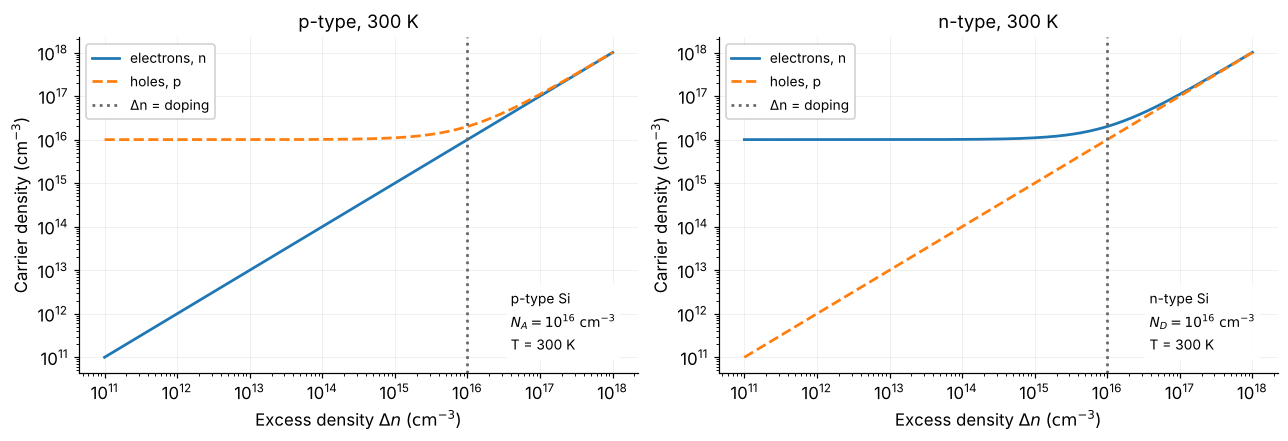

In [2]:
fig = lh.plot_populations(doping=1e16)
plt.show()

The majority-carrier curve starts almost flat: a small added population barely changes the existing reservoir. The minority density follows the added pairs much earlier. At high injection, both totals approach $\Delta n$ and the curves meet. The dashed vertical line marks a crossover, not a sharp change in material physics.

## 2. The generation–recombination balance

Consider a contactless wafer, with no carrier extraction. The quantities $\Delta n$, $G$ and $U_{\mathrm{eff}}$ in Eqs. (4)–(6) are thickness averages. Include the surface loss per unit volume in $U_{\mathrm{eff}}$. The pair balance is

$$
\frac{d\Delta n}{dt}=G-U_{\mathrm{eff}} \tag{4}
$$

$G$ counts externally generated pairs. $U_{\mathrm{eff}}$ is a **net** loss rate: equilibrium thermal generation has already been cancelled against equilibrium recombination. Otherwise a dark wafer would appear to have a finite recombination loss.

Define the effective recombination lifetime as the population divided by its net loss rate:

$$
\tau_{\mathrm{eff}}(\Delta n)=\frac{\Delta n}{U_{\mathrm{eff}}}=\frac{\Delta n}{G-d\Delta n/dt} \tag{5}
$$

A Sinton instrument senses photoconductance; lifetime is inferred using the carrier balance. Sections 9–11 show how the recorded signals supply the quantities in Eq. (5).

This is a population-to-rate ratio. It need not be a single exponential decay constant or a small-signal differential lifetime. At exact equilibrium both numerator and net rate vanish; evaluate the appropriate limit rather than dividing zero by zero.

Under constant illumination after the population has settled, Eq. (4) gives

$$
G=U_{\mathrm{eff}},\qquad\Delta n=G\,\tau_{\mathrm{eff}}(\Delta n) \tag{6}
$$

A longer lifetime lets more carriers accumulate at the same generation rate. Because lifetime can depend on injection, Eq. (6) is generally an implicit equation.

### 2.1 A population filling and emptying

For a constant lifetime $\tau$, a rectangular generation pulse of height $G_0$ and duration $t_{\mathrm{on}}$, starting from no excess carriers, has the solution

$$
\Delta n(t)=\begin{cases}G_0\tau\left(1-e^{-t/\tau}\right),&0\le t\le t_{\mathrm{on}},\\G_0\tau\left(1-e^{-t_{\mathrm{on}}/\tau}\right)e^{-(t-t_{\mathrm{on}})/\tau},&t>t_{\mathrm{on}}.\end{cases} \tag{7}
$$

This deliberately simple illumination explains carrier storage. It is not a simulated Sinton flash or an instrument-analysis exercise.

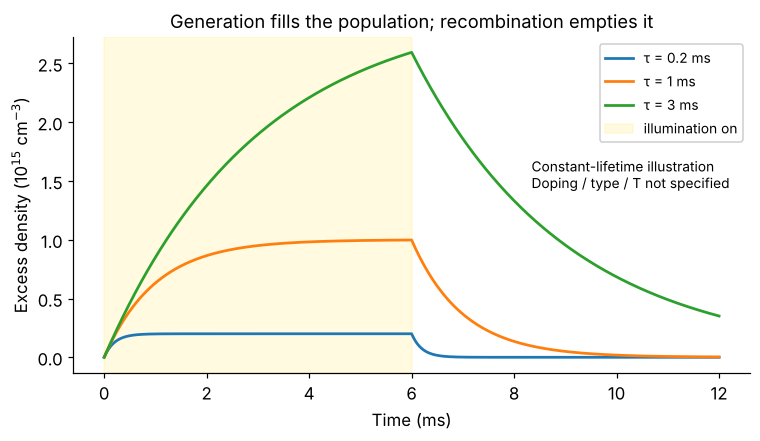

In [3]:
fig = lh.plot_population_balance()
plt.show()

The short-lifetime population reaches its steady level quickly but never becomes large. The long-lifetime population accumulates more carriers and takes longer to disappear after switch-off. For the longest lifetime, the finite light pulse ends before a full steady plateau is reached.

Eq. (5) is the link to the measurement sections. Neglecting storage or neglecting remaining generation are different approximations to the same balance; Section 11 sets out when each is valid.

## 3. Why lifetime is not a material constant

Equation (5) defines a ratio between the carriers present and the rate at which they disappear. Neither quantity is fixed by the word “silicon”. The same wafer has different recombination rates when its carrier population or temperature changes. Defects, doping and surface passivation also change the available loss paths; thickness changes how much surface loss each unit of wafer volume experiences.

A lifetime value therefore belongs to a **sample under stated conditions**. It is not an immutable property like a material label. To understand a curve, first identify the possible loss mechanisms, then combine their rates at the same injection level.

## 4. Four recombination channels and their models

The four panels below distinguish where the recombination energy goes and where the process occurs. Radiative and Auger recombination do not require a defect. Bulk SRH and surface recombination use defect states; the latter additionally depends on the carrier populations at the interface.

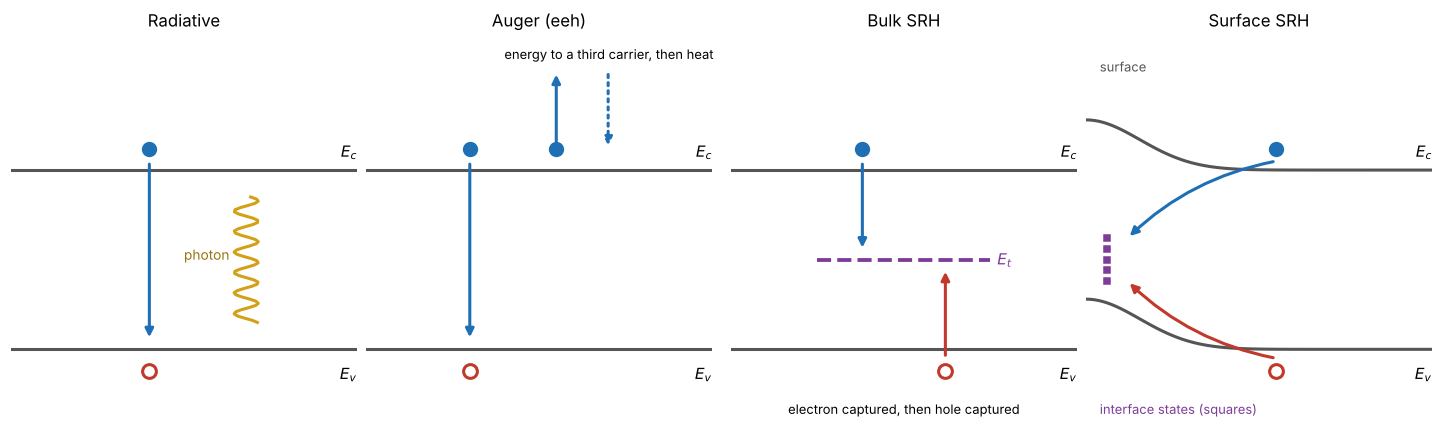

In [4]:
fig = lh.plot_recombination_mechanisms()
plt.show()

*Figure 1. Band-diagram schematics of the four recombination mechanisms. Yellow waves denote an emitted photon. The Auger panel shows energy transfer to an electron (eeh); the hole branch (ehh) is the mirror image. In the bulk SRH panel one trap level captures an electron, then a hole. The surface panel shows the same two captures at interface states, with the bands bent near the surface.*

The band diagrams are schematic. In indirect-gap silicon, radiative transitions also involve lattice momentum; that phonon assistance is not drawn. In both SRH panels, the two arrows represent successive carrier captures, not a direct band-to-band transition.

### 4.1 Defect-assisted recombination: SRH

A defect state can capture one carrier and then the other, returning to its initial charge state after annihilating a pair. For one independent defect level, Shockley–Read–Hall theory gives [[3]](#ref3)[[4]](#ref4)

$$
U_{\mathrm{SRH}}=\frac{np-n_i^2}{\tau_{p0}(n+n_1)+\tau_{n0}(p+p_1)} \tag{8}
$$

The capture time constants are

$$
\tau_{n0}=\frac{1}{N_t\sigma_n v_{\mathrm{th},n}},\qquad\tau_{p0}=\frac{1}{N_t\sigma_p v_{\mathrm{th},p}},\qquad v_{\mathrm{th},j}=\sqrt{\frac{8k_BT}{\pi m_j^*}} \tag{9}
$$

$N_t$ is the bulk defect density and $\sigma_n,\sigma_p$ are capture cross sections. In the thermal-speed expression in Eq. (9), use $k_B$ in $\mathrm{J\,K^{-1}}$ and $m_j^*$ in kg, then convert the speed to $\mathrm{cm\,s^{-1}}$. Use the thermal-speed convention associated with the chosen cross sections. The capture time constants enter the SRH rate in Eq. (8).

Using trap energy relative to the intrinsic level, $\varepsilon_t=E_t-E_i$, makes the auxiliary densities internally consistent:

$$
n_1=n_i e^{\varepsilon_t/(k_BT)},\qquad p_1=n_i e^{-\varepsilon_t/(k_BT)},\qquad n_1p_1=n_i^2 \tag{10}
$$

For several independent bulk defects, evaluate Eq. (8) for each species and add their rates. Both carrier captures must occur for a trap to complete one recombination cycle. Making one capture step slow reduces the total recombination, even if capture of the other carrier is fast.

The example below uses a generic deep level, which is enough to isolate capture asymmetry.

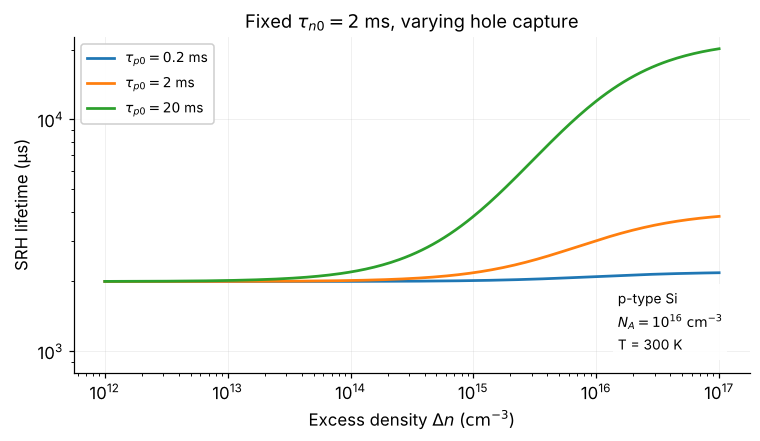

In [5]:
fig = lh.plot_srh_injection()
plt.show()

The low-injection curves nearly coincide because the same electron capture time is used in this p-type example. At larger injection, the time required for the second capture step matters, so the lifetime can increase without any change in defect density. Section 7 returns to this trend after combining all four mechanisms.

### 4.2 Radiative recombination and photon recycling

An electron–hole pair can recombine by emitting a photon. In silicon a phonon participates to conserve crystal momentum, which makes this channel weaker than in a comparable direct-gap material. In the unperturbed, nondegenerate description,

$$
U_{\mathrm{rad,net}}=(1-f_{\mathrm{PR}})B(np-n_i^2),\qquad\tau_{\mathrm{rad,net}}=\frac{\Delta n}{U_{\mathrm{rad,net}}} \tag{11}
$$

$B$ has units $\mathrm{cm}^{3}\,\mathrm{s}^{-1}$. $f_{\mathrm{PR}}$ is the probability that an emitted photon regenerates a pair through band-to-band absorption. Escape or free-carrier absorption does not regenerate a pair. Count recycling in the net loss or as generation, but not in both [[6]](#ref6).

Nguyen et al.'s low-density radiative coefficient is parameterised as [[5]](#ref5)

$$
\begin{aligned}
\log_{10}\!\left(\frac{B_{\mathrm{low}}}{\mathrm{cm}^3\,\mathrm{s}^{-1}}\right)
&=-9.65614-8.05258\times10^{-2}T+6.02695\times10^{-4}T^2\\
&\quad-2.29844\times10^{-6}T^3+4.31934\times10^{-9}T^4
-3.16154\times10^{-12}T^5.
\end{aligned} \tag{12}
$$

Insert the numerical value of $T$ in kelvin in Eq. (12). The study covers 90–363 K. $B$ depends on the intrinsic-density convention used to derive it. In precision calculations the source's emission product $B n_i^2$ is useful for transferring between conventions; using the same numerical $B$ with an unrelated $n_i$ is not automatically consistent.

The carrier-density correction used here is an Altermatt-type form [[14]](#ref14), written using $N_\Sigma=n+p$:

$$
\begin{aligned}B_{\mathrm{rel}}&=b_{\min}+\frac{1-b_{\min}}{1+(N_\Sigma/b_1)^{0.54}+(N_\Sigma/b_3)^{1.25}},\\b_{\min}&=0.20-\frac{0.20}{1+(T/320)^{2.50}},\\b_1&=2\left[1.5\times10^{18}+\frac{10^7-1.5\times10^{18}}{1+(T/550)^3}\right],\\b_3&=2\left[4.0\times10^{18}+\frac{10^9-4.0\times10^{18}}{1+(T/365)^{3.54}}\right].\end{aligned} \tag{13}
$$

$b_1,b_3$ are in $\mathrm{cm}^{-3}$ and temperatures are in K. The factors of two convert a symmetric-plasma density scale to a total-carrier scale. The use for arbitrary $n,p$ is an extension adopted here. The examples in this notebook use $B_{\mathrm{low}}$ alone; `b_relative` evaluates the correction. Use a consistent bandgap-narrowing convention when combining this correction with the Schenk model [[6]](#ref6).

Equation (14) gives the wavelength-averaged recycling probability and the net radiative coefficient. The fraction of emitted photons that fail to regenerate a pair is $1-f_{\mathrm{PR}}$.

$$
\begin{aligned}f_{\mathrm{PR}}&=\frac{\int r_\lambda\,P_{\mathrm{abs}}(\lambda)\,\dfrac{\alpha_{bb}}{\alpha_{bb}+\alpha_{\mathrm{FCA}}}\,d\lambda}{\int r_\lambda\,d\lambda},\\B_{\mathrm{net}}&=B_{\mathrm{low}}B_{\mathrm{rel}}(1-f_{\mathrm{PR}}).\end{aligned} \tag{14}
$$

$r_\lambda$ is emitted-photon spectral weight per unit wavelength; $P_{\mathrm{abs}}$ is the probability of absorption before escape for the specified thickness and optical boundaries. Planar and diffuse surfaces produce different probabilities. Converting an energy spectrum to a wavelength spectrum requires its Jacobian. `photon_recycling_loss` integrates supplied optical arrays; it does not invent them from wafer thickness alone.

The temperature scaling used with the local Schinke absorption table is [[15]](#ref15)

$$
\alpha_{bb}(\lambda,T)=\alpha_{bb}(\lambda,295\,\mathrm K)\left(\frac{T}{295\,\mathrm K}\right)^{295\,\mathrm K\,c_T(\lambda)},\qquad\alpha_{\mathrm{tot}}=\alpha_{bb}+\alpha_{\mathrm{FCA}} \tag{15}
$$

Here $c_T$ is a relative temperature coefficient in $\mathrm{K}^{-1}$. Its product with 295 K is the dimensionless exponent. Table values and their interpolation are inputs; the notebook does not present a tabulated optical dataset as newly validated.

Baker-Finch et al. give doped-region near-infrared fits (with $N$ in $\mathrm{cm}^{-3}$, $\lambda$ in cm and $\alpha$ in $\mathrm{cm}^{-1}$) [[16]](#ref16):

$$
\alpha_{\mathrm{FCA,P}}=1.68\times10^{-6}N\lambda^{2.88},\qquad\alpha_{\mathrm{FCA,B}}=1.82\times10^{-9}N\lambda^{2.18} \tag{16}
$$

Their stated experimental domain is approximately $10^{18}$–$3\times10^{20}$ $\mathrm{cm}^{-3}$ and 1000–1500 nm. Replacing $N$ by the total electron-plus-hole density of a lightly doped, highly injected wafer is an extrapolation, not a validated consequence of those fits. The helper enforces the doped-region domain. This is a reason to audit any optical model before treating its recycling correction as quantitative.

The examples below set $f_{\mathrm{PR}}=0$ (`Sample.f_reabs`). Optical recycling is a property of the wafer and its optical boundaries. It is distinct from the Sinton optical constant $C_{\mathrm{opt}}$ in Section 10.

A radiative event need not be a net loss of one pair if its photon creates another pair in the wafer. This is why the radiative lifetime used in the total must use the net coefficient in Eq. (14).

### 4.3 Auger recombination

In an Auger event the recombination energy is transferred to a third carrier. Separate electron–electron–hole and electron–hole–hole events. The net-rate convention used here is

$$
U_{\mathrm{Aug}}=C_n(n^2p-n_0^2p_0)+C_p(np^2-n_0p_0^2),\qquad\tau_{\mathrm{Aug}}=\frac{\Delta n}{U_{\mathrm{Aug}}} \tag{17}
$$

$C_n,C_p$ have units $\mathrm{cm}^{6}\,\mathrm{s}^{-1}$ and include the chosen carrier-density and temperature dependence. The implementation retains the separate equilibrium subtractions of Eq. (17). Replacing them by a different factorised expression changes the model near equilibrium.

The third carrier takes the released energy, then gives it to the lattice as it thermalises. The eeh and ehh branches have different coefficients because the relevant electronic states and scattering processes differ. A greater carrier population provides more possible three-carrier encounters.

**Temperature-dependent coefficients.**

The helper uses the following temperature-dependent screened coefficients, following Black et al. [[8]](#ref8):

$$
\begin{aligned}C_n^{\mathrm{scr}}(T)&=C_{n,d}^{0}e^{-E_a/(k_BT)}+C_{n,ph}^{0}\coth\!\left(\frac{E_{ph,n}}{2k_BT}\right),\\C_p^{\mathrm{scr}}(T)&=C_{p,ph}^{0}\coth\!\left(\frac{E_{ph,p}}{2k_BT}\right).\end{aligned} \tag{18}
$$

$$
\begin{aligned}C_j&=C_j^{\mathrm{scr}}g_j,\qquad g_j=1+\frac{g_{j,\max}(T)-1}{1+[(n+p)/N_{\mathrm{ref}}(T)]^2},\\g_{j,\max}(T)&=g_{j,\infty}\{1+A\exp[-(T/T_*)^\alpha]\},\qquad N_{\mathrm{ref}}=4\times10^{17}(T/(300\,\mathrm{K}))^4\ \mathrm{cm}^{-3}.\end{aligned} \tag{19}
$$

| Parameter | Electron branch | Hole branch |
|---|---|---|
| $C_{j,d}^0$ ($\mathrm{cm}^{6}\,\mathrm{s}^{-1}$) | $1.02\times10^{-31}$ | omitted |
| $E_a$ (eV) | $2.8\times10^{-3}$ | — |
| $C_{j,ph}^0$ ($\mathrm{cm}^{6}\,\mathrm{s}^{-1}$) | $9.71\times10^{-32}$ | $4.51\times10^{-32}$ |
| $E_{ph,j}$ (eV) | $21.2\times10^{-3}$ | $21.0\times10^{-3}$ |
| $g_{j,\infty}$ | 1.629 | 1.815 |

Shared values are $A=880.9$, $T_*=17.51$ K and $\alpha=0.6434$. Insert these coefficients into Eq. (17). The experimental temperature interval reported in the source is 117–463 K; the combined notebook restricts its other models more tightly. Reproducing a published curve is still required before using this implementation for precision metrology.

The screened coefficient describes the high-density limit. At lower density, carrier correlations enhance the encounter probability; $g_j$ exceeds one. Increasing carrier density screens that interaction, so the enhancement approaches one. Temperature changes both the phonon-assisted terms and the enhancement/screening scales. A fixed 300 K coefficient therefore cannot reproduce the full Black model.

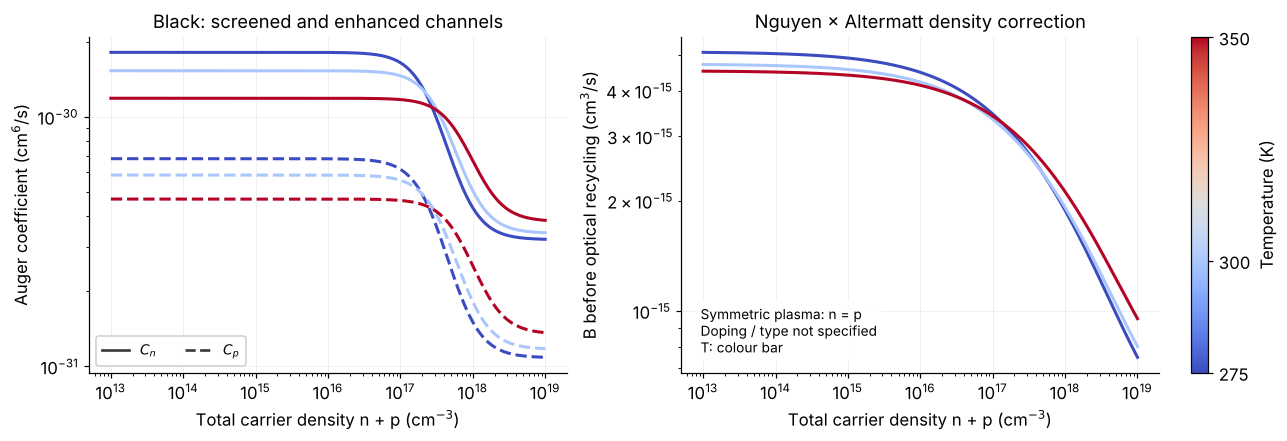

In [6]:
fig = lh.plot_recombination_coefficients()
plt.show()

On the left, the Black coefficients approach their screened values as total density rises. On the right, the radiative density correction reduces $B$ relative to its low-density value. Neither falling coefficient implies that the recombination rate falls: the carrier products multiplying those coefficients are increasing. This distinction becomes central to injection dependence in Section 7.

### 4.4 Interface states, field effect and surface recombination

The surface model separates interface-state density from surface electrostatics [[18]](#ref18)[[19]](#ref19). Useful parameterisations of the energy distribution are

$$
\begin{aligned}D_{\mathrm{gauss}}(E)&=D_{\mathrm{pk}}\exp[-(E-E_{\mathrm{ctr}})^2/(2\sigma_E^2)],\\D_{\mathrm{box}}(E)&=D_{\mathrm{pk}}\,\mathbf{1}_{|E-E_{\mathrm{ctr}}|<w/2},\\D_{\mathrm{tail}}(E)&=D_0\exp\!\left[\ln(D_{\mathrm{end}}/D_0)\frac{E-E_0}{\Delta E}\right].\end{aligned} \tag{20}
$$

$D_{\mathrm{it}}$ is in $\mathrm{cm}^{-2}\,\mathrm{eV}^{-1}$. The helper measures $E$ relative to $E_i$. The centre of a Gaussian or box profile is $E_{\mathrm{ctr}}$. Specify the energy interval and direction of each tail. These functions describe model distributions of interface states.

For each independent state family, the occupation and integrated surface SRH rate are

$$
\begin{aligned}f_t(E)&=\frac{c_n n_s+c_p p_1}{c_n(n_s+n_1)+c_p(p_s+p_1)},\\U_s&=\sum_a\int D_{\mathrm{it},a}(E)\frac{c_{n,a}c_{p,a}(n_sp_s-n_i^2)}{c_{n,a}(n_s+n_1)+c_{p,a}(p_s+p_1)}\,dE,\qquad c_j=\sigma_jv_{\mathrm{th},j}.\end{aligned} \tag{21}
$$

The capture coefficients $c_j$ do not already contain $D_{\mathrm{it}}$. Mixing density-weighted capture quantities with this integral would count the state density twice. For approximately flat quasi-Fermi levels across the surface region,

$$
n_s=n_b e^{q\psi_s/(k_BT)},\qquad p_s=p_b e^{-q\psi_s/(k_BT)},\qquad n_sp_s=n_bp_b \tag{22}
$$

The next plot prescribes $\psi_s$ to expose the physics. It does not infer a fixed charge from a measured lifetime.

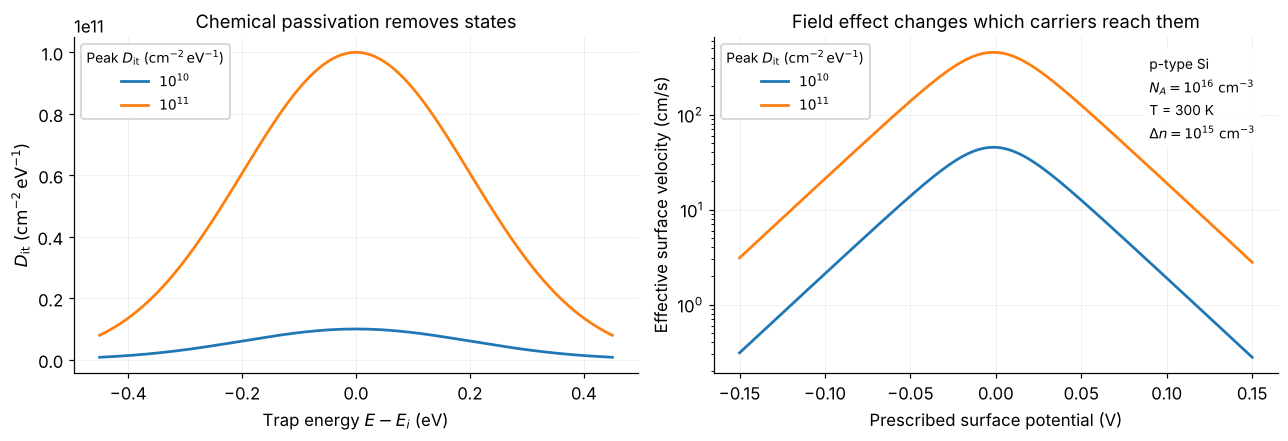

In [7]:
fig = lh.plot_interface_physics()
plt.show()

Reducing $D_{\mathrm{it}}$ lowers recombination at every prescribed surface potential: this is chemical passivation. Changing the potential redistributes electrons and holes while preserving their product in Eq. (22). Strong imbalance reduces the supply of one capture partner and suppresses recombination: this is field-effect passivation. The peak occurs away from flat band because the electron and hole capture terms balance at a nonzero surface potential.

To predict the potential from fixed charge rather than prescribe it, the model must solve electrostatic balance. With charges in $\mathrm{C}\,\mathrm{cm}^{-2}$, one useful nondegenerate form is

$$
\begin{aligned}
Q_{\mathrm{Si}}+Q_{\mathrm{it}}+Q_f+Q_{\mathrm{ext}}+Q_{\mathrm{gate}}&=0,\\
u&=q\psi_s/(k_BT),\\
Q_{\mathrm{Si}}(\psi_s)&=-\operatorname{sgn}(u)\sqrt{2\epsilon_{\mathrm{Si}}k_BT\,F_s(u)},\\
F_s(u)&=p_b(e^{-u}+u-1)+n_b(e^u-u-1),\\
Q_{\mathrm{it}}(\psi_s)&=q\int[D_d(E)(1-f_d(E))-D_a(E)f_a(E)]\,dE.
\end{aligned} \tag{23}
$$

In Eq. (23), $k_BT$ is in joules and $\epsilon_{\mathrm{Si}}$ is in $\mathrm{F\,cm^{-1}}$. $D_d$ and $D_a$ denote donor-like and acceptor-like interface-state densities. Their electron occupancies are $f_d$ and $f_a$. A metal/oxide gate adds a capacitance and work-function-dependent boundary condition; an ungated passivated wafer has $Q_{\mathrm{gate}}=0$. If a charge is quoted as elementary charges per $\mathrm{cm}^{2}$, multiply it by $q$ before using Eq. (23).

The helper's teaching surface plot intentionally takes the potential as input; it is not the full gate/charge solver. Eq. (23) records the physical model required for that more detailed prediction.

If fixed charge fluctuates spatially, averaging the calculated recombination rates gives [[19]](#ref19)

$$
\langle U_s\rangle=\frac{\int U_s(Q)\exp[-(Q-\overline Q)^2/(2\sigma_Q^2)]\,dQ}{\int\exp[-(Q-\overline Q)^2/(2\sigma_Q^2)]\,dQ} \tag{24}
$$

Calculate $U_s(Q)$ after solving each electrostatic state. In general, the rate at the mean charge is not the mean rate. The denominator is retained so that truncating the numerical charge grid does not silently change the total probability.

Finally, a surface saturation-current parameter can be defined as [[9]](#ref9)

$$
qU_s=J_{0s}\left(\frac{n_bp_b}{n_i^2}-1\right),\qquad J_{0s}=\frac{qU_s}{n_bp_b/n_i^2-1} \tag{25}
$$

This definition does not guarantee injection-independent $J_{0s}$. The choice of intrinsic-density convention matters, and the exact equilibrium ratio is undefined. $S_{\mathrm{eff}}$ and $J_{0s}$ are two parameterisations of a surface recombination rate under specified conditions, not direct independent sensor readings.

Surface recombination is therefore more than a fixed number attached to a coating. Chemical passivation reduces active states; field-effect passivation changes which carriers can reach them. A full calculation passes donor/acceptor tails and midgap distributions through a charge-balance solution at each injection, then integrates the SRH loss. The curves in Section 6 use a fixed $S_{\mathrm{eff}}$ and do not need Eq. (24).

Codes differ in their thermal-speed convention (mean or RMS) and sometimes use density-weighted capture arrays. The helper uses explicit $D_{\mathrm{it}}$ and the mean speed in Eq. (9). Keep cross sections and velocity conventions together when transferring parameters.

### 4.5 Carrier statistics shared by the four models

All four mechanisms need the same carrier populations, bandgap and temperature convention. A fuller model uses Pässler for the gap, the Couderc intrinsic-density expression, incomplete ionisation and a Schenk gap correction. The examples in this notebook use full ionisation and no bandgap narrowing so that their limits remain transparent.

<details>
<summary><strong>Model equations: bandgap, intrinsic density, narrowing and ionisation</strong></summary>

#### Bandgap and intrinsic carrier density

The Pässler form used in the helper is [[12]](#ref12)

$$
\begin{aligned}
x&=2T/\Theta,\\
P(x)&=1+\frac{\pi^2x^2}{3(1+\delta^2)}
+\left(\frac{3\delta^2}{4}-\frac14\right)x^3+\frac83x^4+x^6,\\
E_g^0(T)&=E_g^0(0)-a\Theta\left[\frac{1-3\delta^2}{e^{\Theta/T}-1}
+\frac{3\delta^2}{2}\left(P(x)^{1/6}-1\right)\right].
\end{aligned} \tag{26}
$$

The parameters are $E_g^0(0)=1.17$ eV, $a=0.323\times10^{-3}$ $\mathrm{eV}\,\mathrm{K}^{-1}$, $\Theta=446$ K and $\delta=0.51$. The corresponding intrinsic-density expression used here is [[13]](#ref13)

$$
n_i^0(T)=1.541\times10^{15}\,T^{1.712}\exp\!\left[-\frac{E_g^0(T)}{2k_BT}\right]\quad[\mathrm{cm}^{-3}],\qquad T\text{ in K} \tag{27}
$$

The numerical prefactor assumes the stated units. The expression in Eq. (27) is the one given in the reassessment by Couderc, Amara and Lemiti. The temperature panel below shows the resulting variation.

#### Schenk bandgap narrowing

For reproducibility, the algebra below records the Schenk approximation [[17]](#ref17). Let $a_X=3.719\times10^{-7}$ cm and $R_X=0.01655$ eV. Use dimensionless densities

$$
\begin{gathered}\nu_e=n a_X^3,\quad\nu_h=p a_X^3,\quad\nu_D=N_Da_X^3,\quad\nu_A=N_Aa_X^3,\quad F=k_BT/R_X,\\\nu_x=\nu_e+\nu_h,\quad P_x=a_e\nu_e+a_h\nu_h,\quad\nu_I=\nu_D+\nu_A,\quad P_I=a_e\nu_D+a_h\nu_A,\quad H=(\nu_I/F)^2.\end{gathered} \tag{28}
$$

$N_D,N_A$ here are the ionised dopant densities supplied to the model. For branch $j=e,h$, the exchange/correlation term is

$$
\begin{aligned}
\mathcal N_{xc,j}&=(4\pi)^3\nu_x^2\left[(48\nu_j/(\pi g_j))^{1/3}
+c_j\ln(1+d_jP_x^{7/30})\right]\\
&\quad+(8\pi a_j/g_j)\nu_j F^2+\sqrt{8\pi\nu_x}\,F^{5/2},\\
\mathcal D_{xc,j}&=(4\pi)^3\nu_x^2+F^3+b_j\sqrt{\nu_x}\,F^2+40\nu_x^{3/2}F,\\
\delta_{xc,j}&=-\mathcal N_{xc,j}/\mathcal D_{xc,j}.
\end{aligned} \tag{29}
$$

The ionic contribution and resulting gap are

$$
\delta_{I,j}=-\frac{\nu_I(1+H)}{\sqrt{F\nu_I/(2\pi)}\left[1+h_j\ln(1+\sqrt{\nu_I}/F)\right]+j_jH P_I^{3/4}(1+k_jP_I^{z_j})} \tag{30}
$$

$$
\Delta E_g=-R_X\sum_{j=e,h}(\delta_{xc,j}+\delta_{I,j}),\qquad E_g=E_g^0-\Delta E_g,\qquad n_{i,\mathrm{eff}}=n_i^0 e^{\Delta E_g/(2k_BT)} \tag{31}
$$

| Parameter | Electron branch | Hole branch |
|---|---:|---:|
| $g_j$ | 12 | 4 |
| $a_j$ | 0.5187 | 0.4813 |
| $b_j$ | 8 | 1 |
| $c_j$ | 1.3346 | 1.2365 |
| $d_j$ | 0.893 | 1.153 |
| $h_j$ | 3.91 | 4.2 |
| $j_j$ | 2.8585 | 2.9307 |
| $k_j$ | 0.012 | 0.19 |
| $z_j$ | 3/4 | 1/4 |

The zero-ion-density contribution is taken by continuity as zero. The helper evaluates this at a specified carrier population (`schenk_gap_narrowing`). The final relation assumes that gap narrowing changes the exponential carrier factor while the prefactor is unchanged. It does not add Fermi–Dirac degeneracy or an iterative charge-neutrality/BGN solution.

#### Incomplete ionisation

Full ionisation can fail as temperature decreases or dopant conditions change. An isolated-level, nondegenerate model gives

$$
N_D^+=\frac{N_D}{1+g_D(n/N_C)e^{E_D^b/(k_BT)}},\qquad N_A^-=\frac{N_A}{1+g_A(p/N_V)e^{E_A^b/(k_BT)}},\qquad p+N_D^+=n+N_A^- \tag{32}
$$

The equilibrium illustration uses $g_D=2$, $g_A=4$, binding energies 0.045 eV and explicit teaching DOS inputs $N_C(300)=2.86\times10^{19}$, $N_V(300)=3.10\times10^{19}$ $\mathrm{cm}^{-3}$, scaled as $T^{3/2}$. These are a simple isolated-dopant model, not a fitted freeze-out/impurity-band description.

For a quantitative combined model, $N_C,N_V,E_g$ and $n_i$ must be mutually consistent. An illuminated ionisation calculation may also require the relevant quasi-Fermi-level occupations. The main examples avoid those ambiguities by stating full ionisation and using modest wafer doping.

</details>

These equations state the assumptions behind the parameters. The model curves in Sections 6 and 7 use the simpler baseline: full ionisation and no bandgap narrowing.

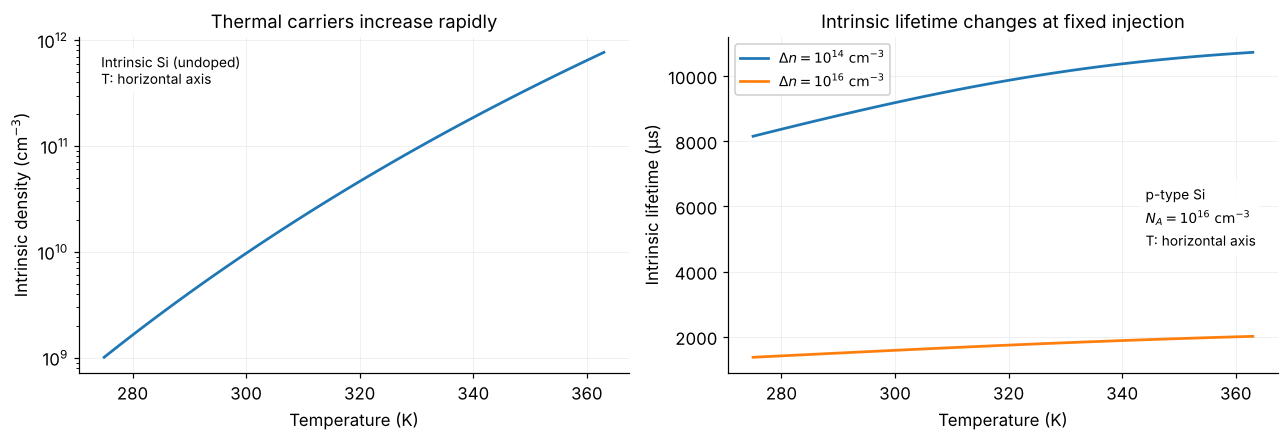

In [8]:
fig = lh.plot_temperature_models()
plt.show()

The intrinsic carrier density rises rapidly with temperature because thermal excitation across the gap becomes easier. At fixed injection the intrinsic lifetime also changes, but its response depends on which channel dominates and on the chosen coefficients. Temperature should be an input to the model, not merely a label added after calculating lifetime.

## 5. Bulk versus surface recombination

A finite wafer has two surfaces as well as a bulk. Defining $\overline{\Delta n}$ as the thickness-averaged excess density, volume integration gives

$$
\overline U_{\mathrm{eff}}=\overline U_{\mathrm{bulk}}+\frac{U_{s,f}+U_{s,r}}{W},\qquad \tau_{\mathrm{eff}}=\frac{\overline{\Delta n}}{\overline U_{\mathrm{eff}}} \tag{33}
$$

The surface flux is per unit area; dividing by thickness converts it to a volume rate. For approximately uniform excess density and effective velocities defined relative to that common bulk density,

$$
S_{\mathrm{eff},f}=\frac{U_{s,f}}{\Delta n},\qquad S_{\mathrm{eff},r}=\frac{U_{s,r}}{\Delta n} \tag{34}
$$

$$
\frac{1}{\tau_{\mathrm{eff}}}=\frac{1}{\tau_{\mathrm{bulk}}}+\frac{S_{\mathrm{eff},f}+S_{\mathrm{eff},r}}{W};\qquad \tau_{\mathrm{surf}}=\frac{W}{2S_{\mathrm{eff}}}\ \text{for equal surfaces} \tag{35}
$$

A microscopic interface capture velocity and $S_{\mathrm{eff}}$ are different quantities. Surface fields change the local carrier populations, so $S_{\mathrm{eff}}$ can depend on injection even when the interface defect distribution stays fixed.

If carrier profiles vary strongly through the wafer, the average in Eq. (33) still matters but the lumped approximation in Eq. (35) is not automatically adequate. Fast diffusion across the wafer relative to recombination favours uniformity; highly absorbing illumination, poor passivation and short bulk lifetime can violate it.

Bulk loss scales with the recombining volume; interface loss scales with area. Two samples can share the same bulk defects yet have different effective lifetimes because their surfaces or thicknesses differ. Conversely, a high-quality surface cannot remove bulk SRH or intrinsic recombination.

A single effective-lifetime curve generally cannot separate those contributions uniquely. Here we **specify** the bulk and surface models to explain their effects; no surface-parameter inversion is attempted.

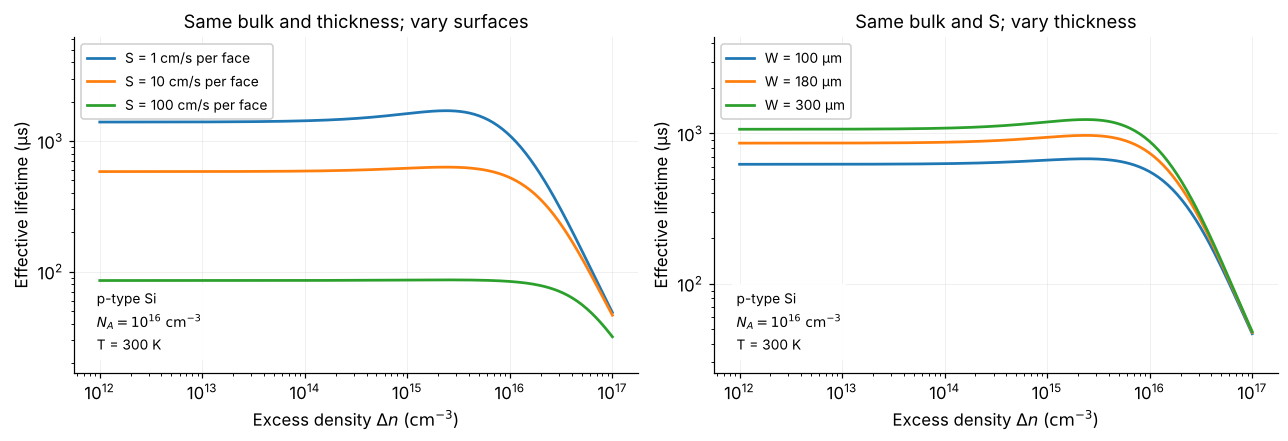

In [9]:
sample = lh.Sample(doping=1e16, kind="p", T=300, W_um=180)
fig = lh.plot_surfaces(sample)
plt.show()

Worse passivation lowers the lifetime without changing the bulk. A thicker wafer reduces the loss per unit volume from the same two surface fluxes. The thickness curves converge as bulk recombination takes over at high injection.

This thickness comparison holds the optical recycling assumption fixed. In a real high-lifetime sample, changing thickness also changes photon recycling; a thickness-series bulk extraction must account for that optical change [[7]](#ref7).

## 6. Combining the four channels into the observed lifetime

All channels act on the same carrier population. Their **net rates** add. Defining $\tau_j=\Delta n/U_j$ gives

$$
\begin{aligned}
U_{\mathrm{bulk}}&=U_{\mathrm{SRH}}+U_{\mathrm{rad,net}}+U_{\mathrm{Aug}},\\
\frac{1}{\tau_{\mathrm{bulk}}}&=\frac{1}{\tau_{\mathrm{SRH}}}
+\frac{1}{\tau_{\mathrm{rad,net}}}+\frac{1}{\tau_{\mathrm{Aug}}}.
\end{aligned} \tag{36}
$$

Adding lifetimes themselves would be wrong. A fast channel removes carriers even if another channel is slow.

$$
\frac{1}{\tau_{\mathrm{eff}}}=\frac{1}{\tau_{\mathrm{SRH}}}+\frac{1}{\tau_{\mathrm{rad,net}}}+\frac{1}{\tau_{\mathrm{Aug}}}+\frac{1}{\tau_{\mathrm{surf}}} \tag{37}
$$

Equation (37) is the construction used for the first lifetime plot below. It describes recombination under the uniform-population approximation; it does not turn photoconductance directly into lifetime. The instrument conversion is in Sections 9–11.

### 6.1 Recombination channels in a model wafer

The curves are computed by `model_examples()` from the four channel models of Section 4, combined through Eq. (37). The baseline is a passivated n-type wafer.

| Input | Baseline used below |
|---|---|
| Wafer | n-type, $N_D=3\times10^{15}$ $\mathrm{cm}^{-3}$; 150 µm; 300 K |
| Bulk SRH | One generic deep level at $E_i$; $\tau_{n0}=2$ ms, $\tau_{p0}=8$ ms |
| Surface | Two equivalent faces; fixed $S_{\mathrm{eff}}=10$ $\mathrm{cm\,s^{-1}}$ each |
| Radiative | $B_{\mathrm{low}}$ from Eq. (12); no photon recycling ($f_{\mathrm{PR}}=0$) |
| Auger | Black coefficients, Eqs. (18)–(19) |
| Excess density | $10^{13}$–$10^{17}$ $\mathrm{cm}^{-3}$ |

These are forward-model curves, not measurements. The surface term is a fixed $S_{\mathrm{eff}}$, so it is flat by construction. Section 4.4 shows why a real surface term varies with injection.

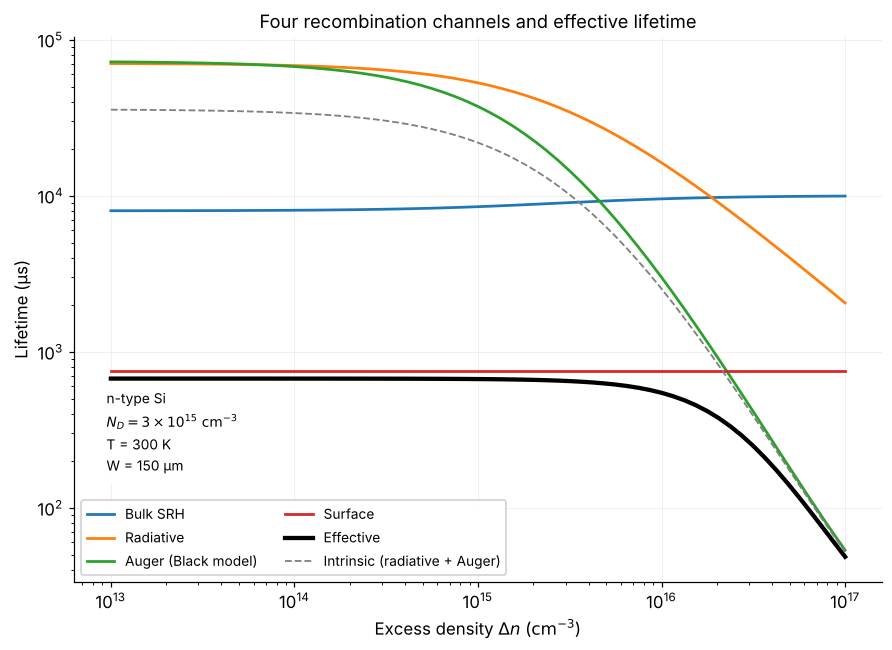

In [10]:
examples = lh.model_examples()
fig = lh.plot_model_components(examples)
plt.show()

At low injection the surface term, $W/(2S_{\mathrm{eff}})=750$ µs, is the shortest of the four lifetimes. It sets the effective lifetime, about 670 µs. Bulk SRH is about 8 ms, and the radiative and Auger lifetimes are longer still. As injection rises, the Auger lifetime falls steeply and drops below the surface term near $2\times10^{16}$ $\mathrm{cm}^{-3}$. Above that it sets the effective lifetime. The black curve lies below every individual component: adding a loss channel can only shorten the total lifetime at a given carrier population.

Where two component lifetimes are equal, their combined lifetime is half either one if other losses are negligible. The black curve therefore does not simply trace the lowest coloured curve.

### 6.2 The intrinsic limit

Even a defect-free bulk retains radiative and Auger recombination:

$$
\frac{1}{\tau_{\mathrm{intr}}}=\frac{1}{\tau_{\mathrm{rad,net}}}+\frac{1}{\tau_{\mathrm{Aug}}} \tag{38}
$$

“Intrinsic” identifies the remaining channels; it does not mean the wafer is undoped. The dashed intrinsic curve in the previous plot is a conditional upper limit for the specified carrier statistics and optical boundaries [[7]](#ref7)[[8]](#ref8). Removing SRH and surface losses does not remove this limit.

### 6.3 Change doping, thickness and temperature

Each panel below changes one input while holding the other sample parameters fixed. The code recomputes every channel for each case. It does not rescale the final effective curve.

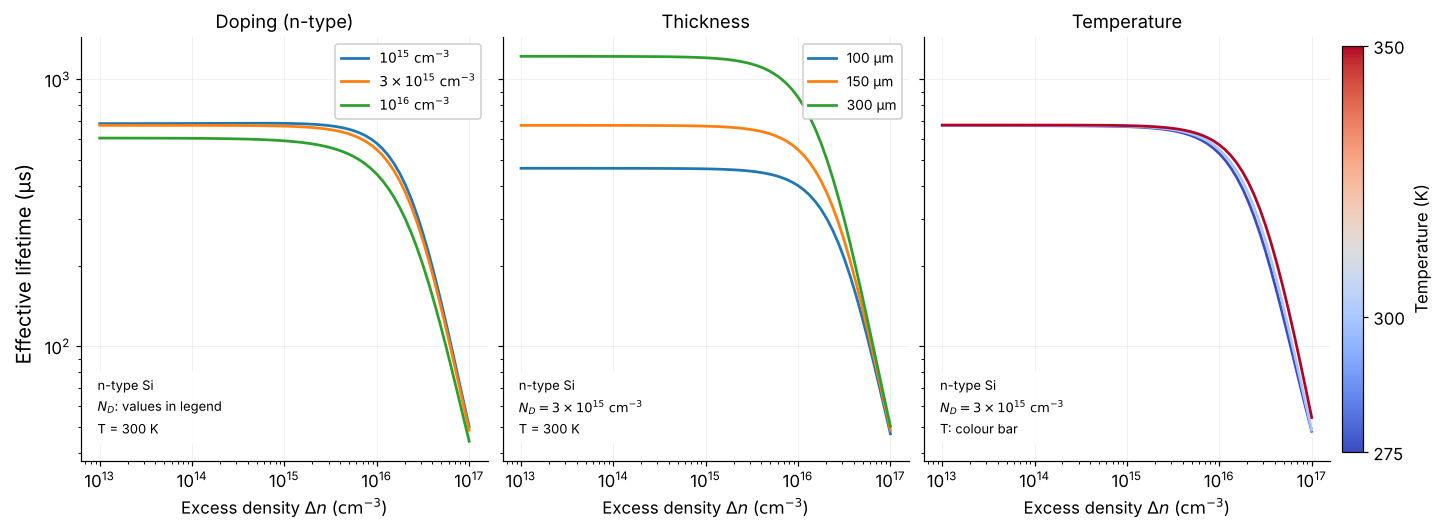

In [11]:
fig = lh.plot_model_comparisons(examples)
plt.show()

**Doping.** More equilibrium carriers increase the opportunities for radiative and Auger events at a given excess density. In this example the low-injection effective lifetime falls from about 680 µs at $10^{15}$ $\mathrm{cm}^{-3}$ to about 600 µs at $10^{16}$ $\mathrm{cm}^{-3}$. The curves approach each other near $10^{17}$ $\mathrm{cm}^{-3}$, where the injected population overtakes the doping and Auger recombination dominates.

**Thickness.** The same surface flux is divided by a larger volume in a thicker wafer, so its contribution to the effective loss rate is smaller. The low-injection lifetime scales almost in proportion to thickness: about 460, 670 and 1200 µs for 100, 150 and 300 µm. The three curves meet near 50 µs at $10^{17}$ $\mathrm{cm}^{-3}$, where Auger recombination dominates and does not depend on thickness.

**Temperature.** The three temperature curves are almost identical at low injection (about 670 µs), where the fixed-$S_{\mathrm{eff}}$ surface term dominates. They separate at $10^{16}$ $\mathrm{cm}^{-3}$: about 530, 545 and 570 µs at 275, 300 and 350 K. This is the combined result of the temperature dependence of the radiative and Auger coefficients and of the carrier statistics. It is not a universal rule that heating improves lifetime. A measured temperature trend should be compared with the individual channels before assigning its cause.

These comparisons use the teaching model and its stated limits. They show trends, not predictions for a real wafer.

## 7. Injection dependence of lifetime

A rising recombination rate does not by itself imply a falling lifetime. Lifetime divides the carrier population by that rate. For positive injection and net recombination rate, compare the slopes on logarithmic axes.

$$
m_j=\frac{d\ln U_j}{d\ln\Delta n},\qquad \frac{d\ln\tau_j}{d\ln\Delta n}=1-m_j \tag{39}
$$

If a rate grows linearly with $\Delta n$, its lifetime is flat. If it grows faster than linearly, lifetime falls. If it grows more slowly, lifetime rises. Equation (39) uses a local slope, so it remains useful when a curve is not a single power law.

### 7.1 Radiative: more electron–hole encounters

At fixed $B_{\mathrm{net}}$, each electron has more available holes as the hole population increases. With injection-independent $n_i$ and $B_{\mathrm{net}}$, substitute Eq. (1) and $n_0p_0=n_i^2$ into Eq. (11) to obtain

$$
\tau_{\mathrm{rad,net}}=\frac{1}{B_{\mathrm{net}}(n_0+p_0+\Delta n)}\ \longrightarrow\ \begin{cases}[B_{\mathrm{net}}(n_0+p_0)]^{-1},&\Delta n\ll n_0+p_0,\\(B_{\mathrm{net}}\Delta n)^{-1},&\Delta n\gg n_0+p_0.\end{cases} \tag{40}
$$

At low injection, the majority reservoir hardly changes, so each added minority carrier has nearly the same recombination probability and lifetime is nearly constant. At high injection both populations increase: the pair rate is approximately quadratic and lifetime falls approximately as $\Delta n^{-1}$. Density-dependent $B$ and photon recycling bend that simple slope.

### 7.2 Auger: the third carrier increases the order

With constant coefficients, the corresponding high-injection limit is

$$
U_{\mathrm{Aug}}\simeq(C_n+C_p)\Delta n^3,\qquad\tau_{\mathrm{Aug}}\simeq\frac{1}{(C_n+C_p)\Delta n^2} \tag{41}
$$

The additional carrier supplies one more population factor. At low injection, the majority-assisted branch can instead be approximately linear in excess density, giving a plateau. In the Black model, screening reduces Coulomb enhancement as density rises; it moderates the growth of the rate but does not remove the three-carrier encounter term. The $-2$ slope is therefore a useful limiting reference, not a requirement for every part of the curve.

### 7.3 Bulk SRH: occupancy and two capture steps

The trap must capture both carrier types to complete a cycle. When one species is scarce, capture of that species can control the rate. As injection changes the populations, it also changes trap occupancy and the relative importance of the two capture steps.

For a single deep trap, the low-injection limits below require the majority-carrier term to dominate the denominator of Eq. (8). In p-type material this requires $\tau_{p0}(n+n_1)\ll\tau_{n0}p_0$ and $p_1\ll p_0$. In n-type material it requires $\tau_{n0}(p+p_1)\ll\tau_{p0}n_0$ and $n_1\ll n_0$. In the high-injection limit, $\Delta n$ dominates $n_0,p_0,n_1,p_1$.

$$
\tau_{\mathrm{SRH}}\simeq\begin{cases}\tau_{n0},&\text{low injection, p-type},\\\tau_{p0},&\text{low injection, n-type},\\\tau_{n0}+\tau_{p0},&\text{high injection}.\end{cases} \tag{42}
$$

Through the crossover, the SRH rate can rise more slowly than $\Delta n$, so $\tau_{\mathrm{SRH}}$ rises at fixed defect density. At high injection, both capture terms grow with $\Delta n$, and the rate approaches linear growth again. Trap energy, multiple defects and temperature-dependent capture can change the shape of this transition.

### 7.4 Surface: capture plus an injection-dependent electric field

Surface states follow the same sequential-capture physics, but they see $n_s,p_s$, not just the bulk populations. At fixed interface charge, increasing injection changes charge screening and hence $\psi_s$. This changes the supply of carriers to interface states even though the density of those states is unchanged.

A prescribed constant $S_{\mathrm{eff}}$, as used in Sections 6 and 7, gives a flat $W/(2S_{\mathrm{eff}})$ by construction. A real passivated surface with fixed charge does not. As injection rises, the charge is screened, the field weakens and $U_s/\Delta n$ generally changes. Other charge polarities, doping types and capture asymmetries can give rising, falling or nonmonotonic surface lifetimes. Section 4.4 shows the mechanism; the surface panel below is flat only because $S_{\mathrm{eff}}$ is fixed.

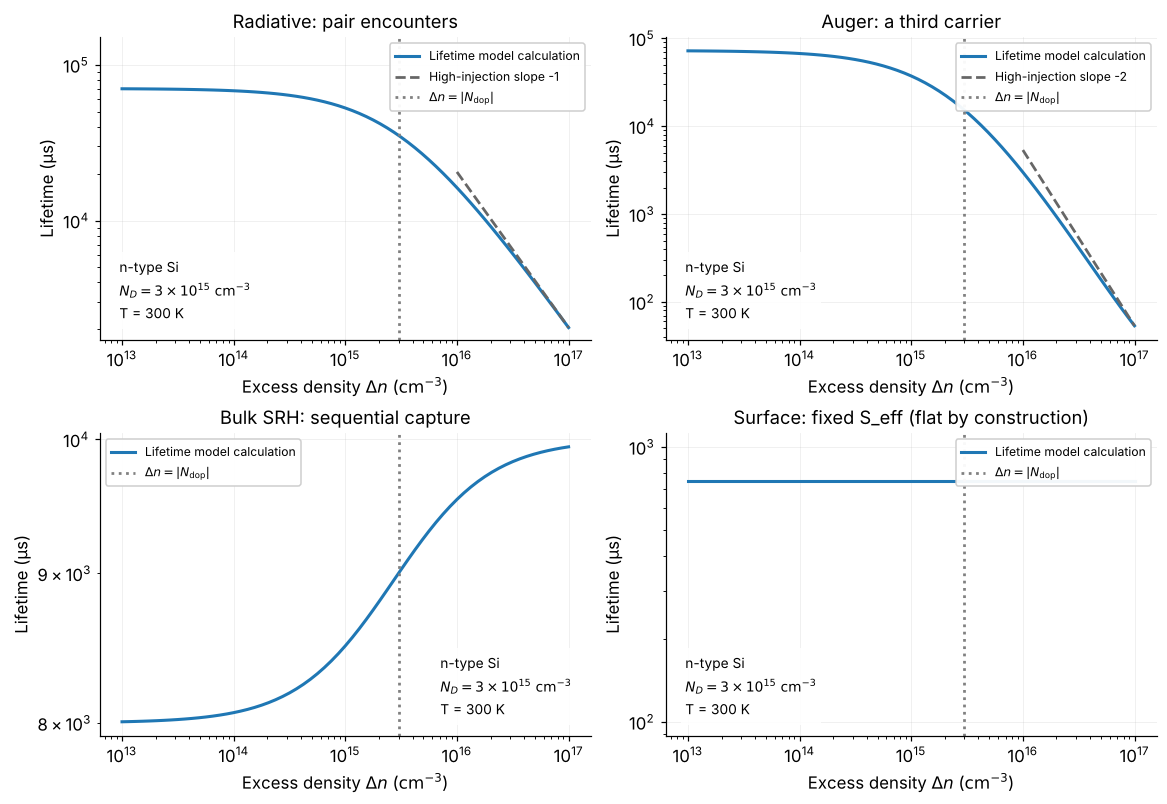

In [12]:
fig = lh.plot_injection_channels(examples)
plt.show()

The four panels refer to the same sample as Section 6. The radiative and Auger lifetimes turn downward as high injection is approached. SRH rises slowly towards a plateau as the second capture step matters. The surface lifetime is flat because $S_{\mathrm{eff}}$ is fixed. The combined curve is flat at low injection, where the surface term dominates, and then falls as Auger recombination takes over. It is therefore incorrect to require all four lifetimes to decrease monotonically.

The dashed slopes show constant-coefficient high-injection limits. Departures from them are expected where injection is not yet high relative to doping or where coefficients, optics or electrostatics vary with density.

### 7.5 Quote lifetime at a specified excess density

A maximum lifetime discards where that value occurred. Two samples can even exchange their ranking as injection changes, with no alteration of either sample during the comparison.

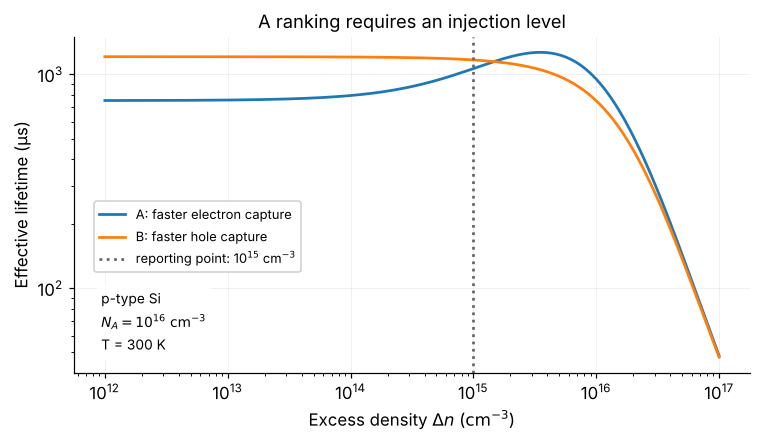

In [13]:
fig = lh.plot_ranking()
plt.show()

Sample B has the longer lifetime at low injection. Sample A overtakes it as the different capture asymmetries matter. “A is better than B” therefore needs a specified operating condition.

For a single value, report $\tau_{\mathrm{eff}}$ at a stated $\Delta n$, together with temperature, doping, thickness and passivation state. $\Delta n=10^{15}$ $\mathrm{cm}^{-3}$ is a useful common reporting point, also recommended by Sinton, but it must fall inside the valid measured range [[10]](#ref10). Keep the full curve whenever possible.

## 8. Voltage implied by lifetime

Illumination separates the electron and hole quasi-Fermi levels. Under nondegenerate statistics, using the same intrinsic-density convention as the carrier model, the implied voltage is [[11]](#ref11)

$$
\begin{aligned}
V_{\mathrm{imp}}&=\frac{E_{Fn}-E_{Fp}}{q}=\frac{k_BT}{q}\ln\!\left(\frac{np}{n_i^2}\right)\\
&=\frac{k_BT}{q}\ln\!\left[\frac{(n_0+\Delta n)(p_0+\Delta n)}{n_i^2}\right].
\end{aligned} \tag{43}
$$

Use joules for $E_{Fn}-E_{Fp}$ and $k_B$ in $\mathrm{J\,K^{-1}}$ when dividing by $q$. The helper instead uses $k_B$ in $\mathrm{eV\,K^{-1}}$, so $k_BT$ gives the numerical thermal voltage in volts directly.

Equation (43) gives the voltage from the carrier densities. Lifetime determines those densities through the generation balance. For an absorbed pair-generation equivalent current density $J_{\mathrm{gen}}$ at open circuit,

$$
G=\frac{J_{\mathrm{gen}}}{qW}=U_{\mathrm{eff}}(\Delta n)=\frac{\Delta n}{\tau_{\mathrm{eff}}(\Delta n)} \tag{44}
$$

Here $J_{\mathrm{gen}}$ is a convenient way to express absorbed generation, not a measured terminal short-circuit current. Calling the result one-sun implied $V_{oc}$ additionally requires a justified one-sun generation calibration. The example uses an explicitly assumed 40 $\mathrm{mA}\,\mathrm{cm}^{-2}$ generation equivalent.

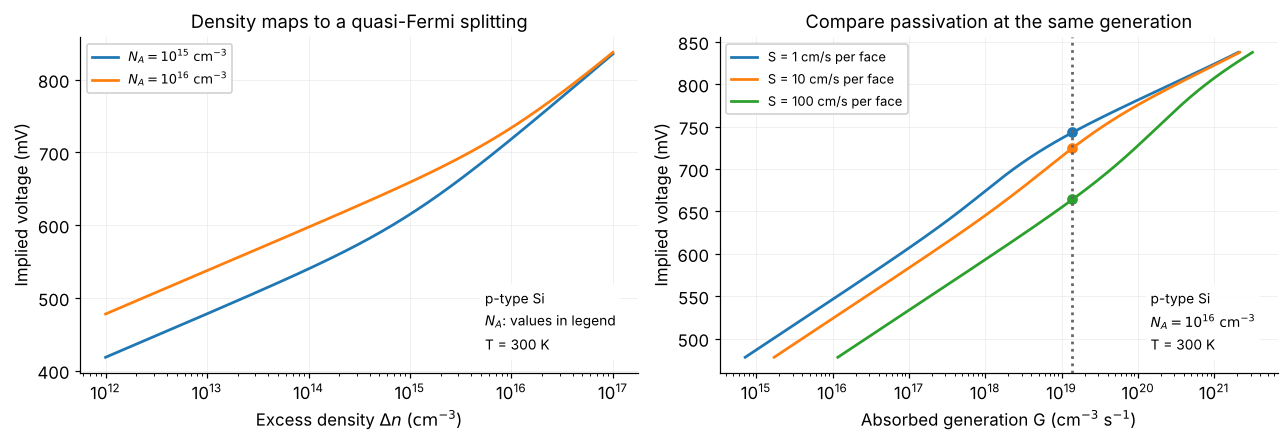

S=  1 cm/s: delta_n=1.259e+16 cm^-3, implied voltage=743.0 mV
S= 10 cm/s: delta_n=7.817e+15 cm^-3, implied voltage=724.5 mV
S=100 cm/s: delta_n=1.195e+15 cm^-3, implied voltage=664.0 mV


In [14]:
fig, voltage_examples = lh.plot_voltage()
plt.show()
lh.print_voltage_examples(voltage_examples)

On the left, density maps to voltage through doping and carrier statistics. On the right, improving passivation permits a larger carrier population at the same generation rate, so the marked operating voltage increases.

For fixed doping and temperature, two samples at the same $\Delta n$ have the same implied voltage in this model even if their lifetimes differ. Their **required generation rates** differ. Compare passivation at the same illumination when discussing voltage gains.

An implied voltage characterises the carrier population in the precursor wafer. Contact recombination, spatially varying quasi-Fermi levels and other losses in a finished device can lower the terminal $V_{oc}$. Bandgap narrowing and degeneracy also require a consistent extension of Eq. (43); simply inserting unrelated intrinsic-density values is not sufficient.

## 9. Components and operation of the Sinton machine

The Sinton lifetime measurement system combines a **xenon flash lamp**, an **inductively coupled coil** and a **calibrated reference cell**, arranged around the wafer as shown in Figure 2.

The flash lamp illuminates the wafer, generating excess electron–hole pairs. A long-pass filter and diffusers shape the illumination: the filter favours more deeply penetrating light, while the diffusers help distribute it across the sample.

These excess carriers increase the wafer’s conductance. The coil beneath the wafer senses this change **inductively, without electrical contacts**. Its calibrated response gives the photoconductance, which is converted into the excess carrier density $\Delta n(t)$ using the wafer thickness and the electron and hole mobilities.

At the same time, the calibrated reference cell records the time-dependent light intensity. Together with the sample’s optical constant and thickness, this signal gives the generation rate $G(t)$ inside the wafer.

The instrument therefore provides two complementary quantities: **how many excess carriers are present**, $\Delta n(t)$, and **how quickly light generates them**, $G(t)$. Combining these with the rate of change of the carrier population gives the effective lifetime through the carrier-balance equation of Section 2. The following sections explain each conversion and its calibration.

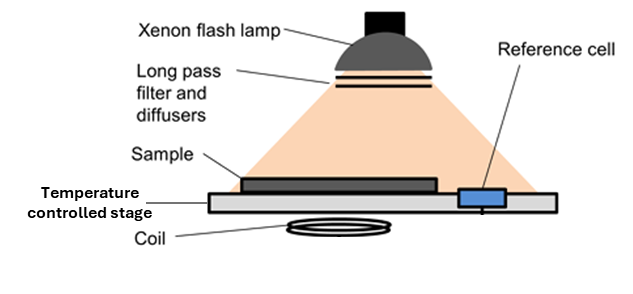

In [15]:
display(lh.instrument_figure())

Figure 2. Schematic of the Sinton measurement arrangement, showing the xenon flash lamp, long-pass filter and diffusers, sample, inductive coil and reference cell. 

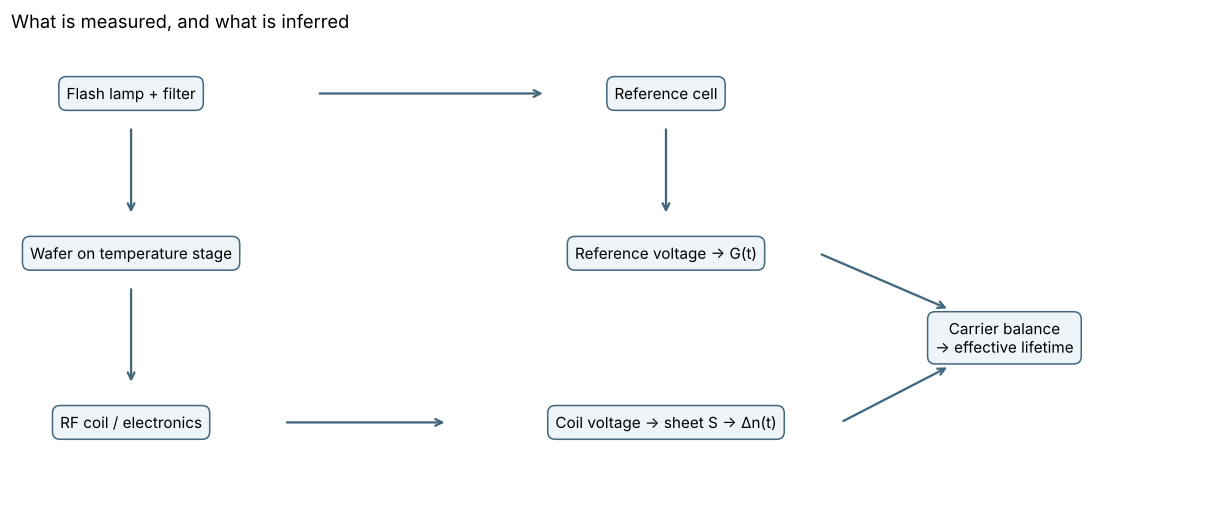

In [16]:
fig = lh.plot_instrument()
plt.show()

*Figure 3. What the instrument records (left) and what is inferred from it (right). Each arrow is a calculation with its own assumptions, set out in Sections 10 and 11.*

### 9.1 Two example exports

The notebook uses two real exports from one n-type wafer, 200 µm thick, about 1 Ω cm, near 300 K. One is a **short flash** analysed in transient mode. The other is a **full flash** analysed in generalised mode. Both are embedded in the helper. To use your own files, replace the two `example_measurement` calls in the cell below with `lh.load_sinton('your_file.txt')`.

Figure 4 shows what the instrument actually recorded for each flash: the coil channel, the reference channel and the density inferred from the coil channel.

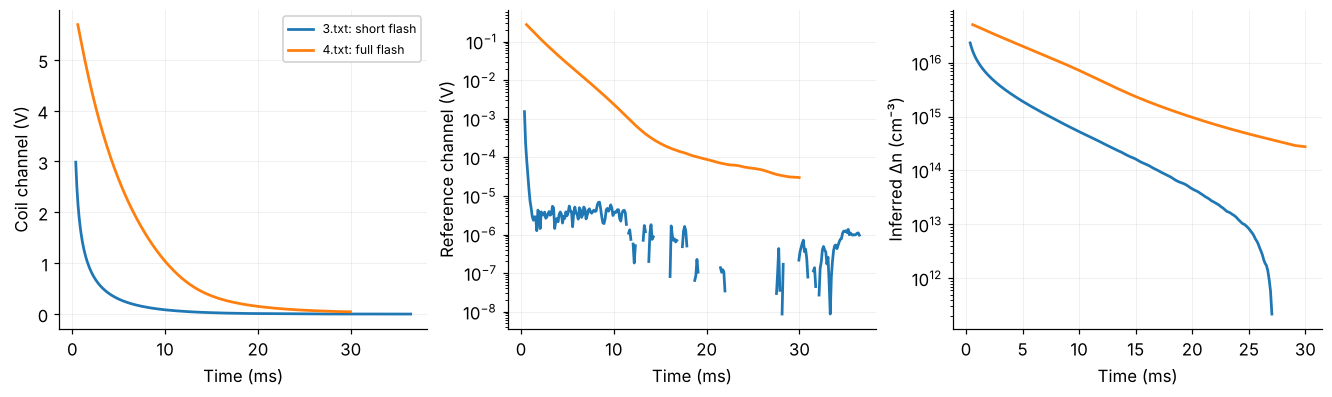

In [17]:
short_measurement = lh.example_measurement('3.txt')   # short flash
full_measurement = lh.example_measurement('4.txt')    # full flash
short = lh.analyse_measurement(short_measurement)     # transient mode, as exported
full = lh.analyse_measurement(full_measurement)       # generalised mode, as exported

fig = lh.plot_raw_measurements(short, full)
plt.show()

*Figure 4. Recorded channels for the two example exports (left, centre) and the excess density inferred from the coil channel (right). The short flash switches off within about 1 ms, so its reference channel falls to the noise level. The full flash decays over tens of milliseconds, and its reference channel stays above noise throughout.*

## 10. From recorded signals to carrier density and generation

### 10.1 Zero, dark and illuminated readings are different

**Air zero** is measured with the sample absent. **Dark voltage** is measured with the sample present but without excess illumination. **Illuminated voltage** contains both the equilibrium conductance and its light-induced change. Subtracting the dark *voltage* before applying a nonlinear calibration is generally different from subtracting the calibrated dark *conductance*.

For one explicit calibration convention, define $x=V_{\mathrm{sample}}-V_{\mathrm{air}}$ and write

$$\Sigma_{\mathrm{app}}=A_c x^2+B_c x+C_c.\tag{45}$$

The polynomial is empirical and is only supported over its calibrated voltage and conductance range. A voltage-offset representation, $A_c(x+v_0)^2+B_c(x+v_0)$, is another convention: its expanded linear and constant coefficients differ. Do not copy an offset into $C_c$, whose units are siemens.

The reference plane and sensitivity normalisation must also match the fitted coefficients. In the **absolute thin-sheet convention** used here, the sensitivity is unity for an infinitesimal conducting layer at the fitted zero-depth plane. The refined Black–Macdonald attenuation model is [[20]](#ref20)

$$s_c(z)=\frac{1}{(1+z/\lambda_c)^2\,[1+(z/(2\lambda_c))^2]}.\tag{46}$$

For uniform conductivity over thickness $W$, the corresponding average and correction are

$$\bar s_c(W,\Delta z)=\frac{1}{W}\int_{\Delta z}^{\Delta z+W}s_c(z)\,dz,
\qquad \Sigma=\frac{\Sigma_{\mathrm{app}}}{\bar s_c}.\tag{47}$$

All three geometric lengths must share a unit in these equations. The helper uses mm for this integration. Zero lift-off denotes the stage plane of the calibration; it does not imply that the wafer touches the metal coil. A reference-wafer-normalised calibration instead needs the appropriate sensitivity ratio. Applying an absolute correction to coefficients from the other convention creates a systematic scale error.

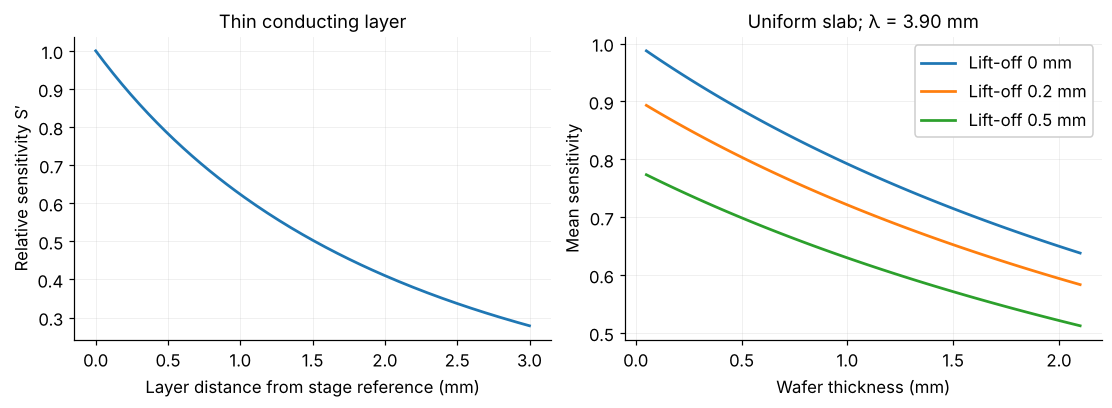

In [18]:
fig = lh.plot_sensitivity(lambda_mm=3.9)
plt.show()

*Figure 5. Modelled attenuation with depth, thickness and lift-off. The illustrative attenuation length is 3.9 mm. A spacer or a change in thickness changes the conductance inferred from the same sensor response.*

### 10.2 Fit the coil using known standards and ordered stacks

The calibration data embedded in the helper contain four 525 µm standards, with sheet resistances 4.201, 12.4, 48.48 and 144.3 Ω/□, measured singly and in every ordered stack: 4 singles, 12 pairs, 24 triples and 24 quadruples. Three voltage replicates are averaged for each configuration, using the air zero for its measurement date. Total known conductances span approximately 0.00693–0.346 S; stacked thicknesses span 0.525–2.10 mm.

Different stack orders matter because the more conductive layer contributes less when placed farther from the coil. For stack $k$, the known sensitivity-weighted target is $y_k(\lambda_c)=\sum_i\Sigma_{ki}\bar s_{c,i}(\lambda_c)$. We fit the relative residuals:

$$Q(\lambda_c)=\min_{A_c,B_c,C_c}\frac{1}{N}\sum_{k\in\mathrm{fit}}
\left[\frac{A_c x_k^2+B_c x_k+C_c-y_k(\lambda_c)}{y_k(\lambda_c)}\right]^2.\tag{48}$$

At **every** trial $\lambda_c$, the polynomial is re-fitted. Singles and pairs determine the fit below; triples and quadruples assess transfer to larger stacks. Unlike a uniformly doped wafer, a stack of differently doped standards cannot be corrected using a single uniform-slab sensitivity. The helper reconstructs the conductance of successive layers from differences between measured stack prefixes, then divides each increment by its own sensitivity. This assumes unchanged lower layers, negligible gaps and stable response across dates.

Attenuation length: 3.5613 mm
A_c, B_c, C_c: [ 0.00033456  0.0289287  -0.00035247] (S/V², S/V, S)


         N  mean_error_percent  mean_absolute_error_percent
layers                                                     
1        4              -0.362                        0.648
2       12               0.255                        0.570
3       24               3.940                        3.966
4       24               3.795                        3.795

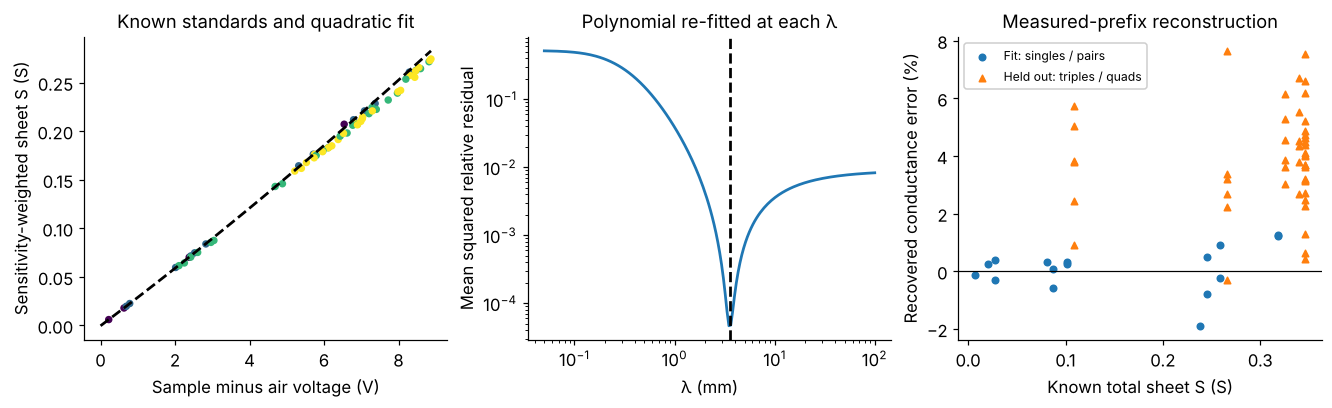

In [19]:
coil = lh.fit_coil_calibration(max_training_layers=2)
print(f"Attenuation length: {coil['lambda_mm']:.4f} mm")
print('A_c, B_c, C_c:', coil['coefficients'], '(S/V², S/V, S)')
display(coil['summary'].round(3))
fig = lh.plot_coil_calibration(coil)
plt.show()

*Figure 6. The measured standards, the re-fitted objective and conductance recovery errors. The larger stacks are held out of parameter fitting; their measured prefixes are still required for reconstruction.*

The roughly 4% mean error in the larger stacks is a limitation of this calibration transfer, not a reason to hide the verification points. Possible contributions include gaps, cross-date drift and departures from the assumed response. The residuals alone do not identify which contribution dominates. The fitted negative intercept also warns against extending the polynomial toward zero conductance. A 200 µm sample lies below the thinnest standard: the thickness correction there is model-based extrapolation that should be checked with an appropriate thin standard.

Black and Macdonald's estimate of uncertainty in their attenuation length is not an uncertainty for our fitted value. Here the repeated voltage spread is only one contribution; standard resistance, thickness, lift-off, drift and model discrepancy remain. The embedded calibration data and the two lifetime exports are separate examples without a demonstrated shared calibration history. We do **not** apply the new coil fit retrospectively to the lifetime traces without the matching air zero and calibration history.

### 10.3 Convert conductance to excess density

Under the uniform, quasi-neutral paired-carrier approximation, the total sheet conductance is

$$\Sigma(\Delta n)=qW\left[\mu_n(\Delta n)(n_0+\Delta n)
+\mu_p(\Delta n)(p_0+\Delta n)\right].\tag{49}$$

Its measured change is

$$\Delta\Sigma=\Sigma(\Delta n)-\Sigma(0).\tag{50}$$

Only if mobilities can be treated as unchanged does this reduce to $\Delta\Sigma=qW(\mu_n+\mu_p)\Delta n$. With injection-dependent mobility (the Klaassen model [[25]](#ref25)), the majority carriers already present in the dark also change their contribution. The helper therefore reconstructs the **total** sheet conductance and solves Eq. (49) implicitly by bracketed root finding. It reports invalid sub-dark points as missing rather than forcing them into a positive density.

For these exports, the working interpretation is that `Conductivity_(Siemens)` is **excess sheet conductance**, despite its name. We add $1/R_{\mathrm{sheet,dark}}$ to obtain the total. The measured resistivity is consistent with $W R_{\mathrm{sheet,dark}}$. Do not repeat the coil correction on this already-calibrated column. For a different exporter, verify its column convention first.

Dark resistivity can estimate doping if the type is known and conduction is due to a uniformly doped bulk. That is an inference using a mobility model, not an independent doping measurement. Conducting films, diffused layers, compensation and incomplete ionisation can invalidate it. The helper solves equilibrium neutrality exactly; the older approximation $n_{\mathrm{maj},0}=N+n_i$ does not satisfy both neutrality and the mass-action relation.

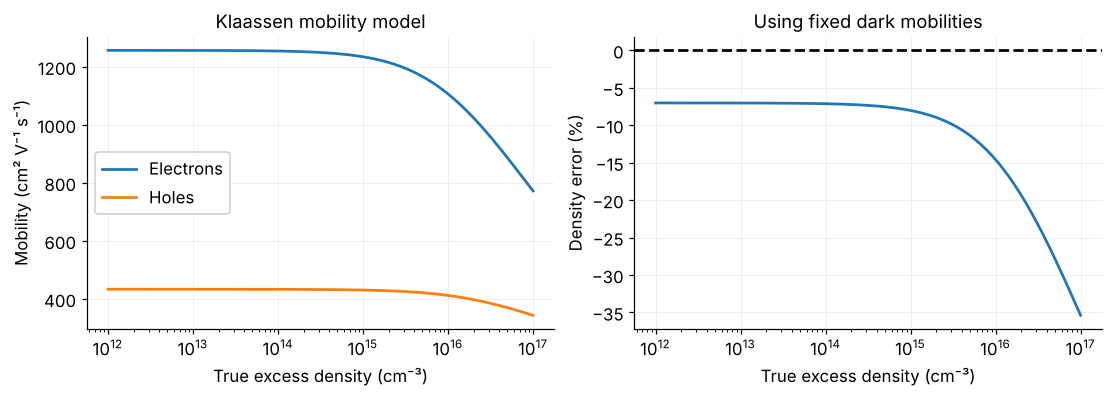

Dark-resistivity inferred doping: short 5.558e+15, full 5.581e+15 cm⁻³


In [20]:
fig = lh.plot_mobility()
plt.show()
print(f"Dark-resistivity inferred doping: short {short['doping']:.3e}, full {full['doping']:.3e} cm⁻³")

*Figure 7. Synthetic n-type example at 300 K with $N_D=5\times10^{15}$ cm$^{-3}$. Mobilities change with injection; using their dark values gives a systematic density error. This demonstrates the implementation in the helper, not an independent validation of the complete Klaassen model.*

### 10.4 Convert reference voltage to generation

Let $k_{\mathrm{ref}}$ be the reference voltage per calibrated sun-equivalent and $V_{\mathrm{ref},0}$ the reference-channel offset. Then

$$f_{\mathrm{ref}}=\frac{V_{\mathrm{ref}}-V_{\mathrm{ref},0}}{k_{\mathrm{ref}}},\qquad
G=\frac{f_{\mathrm{ref}}C_{\mathrm{opt}}J_{\mathrm{ref}}}{qW}.\tag{51}$$

$f_{\mathrm{ref}}$ is dimensionless relative illumination, **not** a photon flux. Dividing the generation-current density by $q$ supplies a pair flux in cm$^{-2}$ s$^{-1}$; dividing by thickness gives the required volume rate. The helper uses $J_{\mathrm{ref}}=0.038$ A/cm$^2$ and $k_{\mathrm{ref}}=0.0113756$ V/sun. The former is the Sinton optical-constant convention; the latter is a value carried over from earlier analysis and is not recorded in the exports.

$C_{\mathrm{opt}}$ includes sample absorption and the conversion between the flash/reference response and this generation convention. It is an **effective scale**, so values greater than one are possible. It is not simply the fraction of incident photons absorbed. A change in texture, coating, thickness, spectrum, filter, aperture or illumination geometry can require reassessment.

For reference-cell calibration, use an independently known illumination or generation standard with the same aperture, spectrum and geometry; record a dark offset and verify linearity over several intensities. `reference_calibration` fits gain and offset to such records. No independent reference-standard dataset is included here, so the numerical reference gain is not re-calibrated. Mode matching constrains $C_{\mathrm{opt}}/k_{\mathrm{ref}}$: it cannot determine both quantities independently.

## 11. From carrier density and generation to lifetime

### 11.1 One balance equation, three analyses

With no external carrier extraction, thickness-averaged pair balance gives

$$U_{\mathrm{eff}}=G-\frac{d\Delta n}{dt},\qquad
\tau_{\mathrm{gen}}=\frac{\Delta n}{G-d\Delta n/dt}.\tag{52}$$

This repeats Eq. (5) in the measurement notation. Surface flux is already included in $U_{\mathrm{eff}}$. We do not discard surface recombination by setting a local current-divergence term to zero. Spatially nonuniform generation and carrier profiles can nevertheless make the coil-weighted signal differ from the uniform volume average assumed by the inversion.

**Quasi-steady state** neglects carrier storage. Define a directly measurable diagnostic:

$$\tau_{\mathrm{QSS}}=\frac{\Delta n}{G},\qquad
\epsilon_{\mathrm{QSS}}=\frac{|d\Delta n/dt|}{G}\ll1.\tag{53}$$

Relative to Eq. (52), the absolute fractional lifetime error is exactly $\epsilon_{\mathrm{QSS}}$ when both rates are physical. During decay, neglecting storage overestimates lifetime. For an exponential flash of time constant $t_f$ and a constant lifetime after the initial fast response, the error is $\tau/(t_f-\tau)$ for $\tau<t_f$. Thus $\tau\approx t_f/10$ gives about 11% error, not a mathematical guarantee of steady state. The familiar 200 µs guideline for a roughly 2 ms flash is a practical scale comparison; the measured rate ratio is the better criterion.

**Transient** analysis neglects remaining generation:

$$\tau_{\mathrm{tr}}=-\frac{\Delta n}{d\Delta n/dt}
=-\left(\frac{d\ln\Delta n}{dt}\right)^{-1},\qquad
\epsilon_{\mathrm{tr}}=\frac{G}{-d\Delta n/dt}\ll1.\tag{54}$$

On a decreasing-density branch, the fractional overestimate relative to Eq. (52) is exactly $\epsilon_{\mathrm{tr}}$. A short flash helps, but the first points after it may still contain substantial generation. Reject or analyse those points with the generalised expression. Transient lifetime itself does not need an optical constant once generation is negligible; confirming negligible generation and converting to a one-sun implied voltage still need optical information.

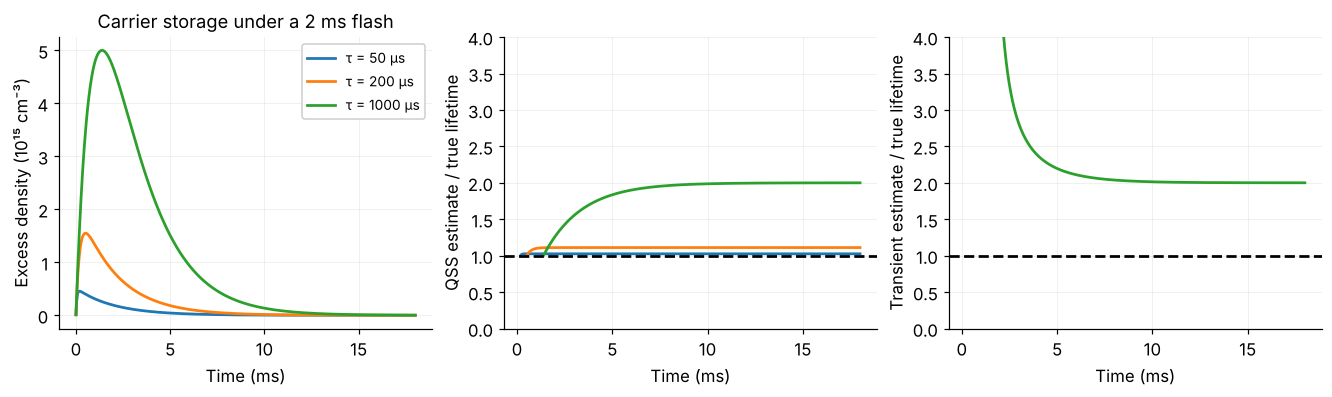

In [21]:
fig = lh.plot_mode_limits()
plt.show()

*Figure 8. Exact synthetic constant-lifetime responses to an exponentially decaying 2 ms flash. The generalised expression returns the chosen true lifetime; the two approximations fail in different ways. Only the decay branch is shown in the lifetime-ratio panels, and ratios above four are outside the plotted range.*

| Analysis and flash | Use when | Main limitation |
|---|---|---|
| QSS, long/full flash | Storage is small compared with generation | Requires calibrated generation; fails as storage grows |
| Generalised, long/full flash | Storage matters and sufficient injection is needed | Requires both calibrated generation and a reliable derivative |
| Generalised, short flash | Residual generation is not yet negligible, including intermediate lifetimes | Particularly useful where a pure transient assumption is premature |
| Transient, short flash | Generation is negligible during the selected decay interval | May not reach the target injection; derivative noise and early residual light matter |

Instrument documentation gives approximate 200 µs and 800 µs lifetime guidelines for particular flash configurations. These are operating guidance, not universal physical boundaries. Generalised short-flash analysis has a useful role between the regimes and should not be discarded. Characterise the actual flash waveform. The embedded exports were produced by instrument software v6.0; check your own hardware settings rather than assuming they match.

### 11.2 Differentiate the trace without inventing a tail

Numerical derivatives amplify noise. We locally fit $\ln\Delta n(t)$ with a quadratic Savitzky–Golay filter on a uniform time grid and recover $d\Delta n/dt=\Delta n\,d\ln\Delta n/dt$. Each contiguous positive segment is treated separately. We exclude half a window at its boundaries, rising-density points and nonpositive recombination rates. The time grid must be strictly increasing and uniformly spaced; irregular sampling requires a different local regression rather than substituting an average time step.

A common shortcut switches windows at fixed injection thresholds, or replaces nonpositive densities by a tiny positive number before taking logarithms. Such operations can introduce features unrelated to recombination. Here window choice is explicit, and invalid points stay invalid. Wider smoothing reduces noise but can erase real curvature and distort the early decay; inspect multiple windows rather than selecting whichever curve looks best.

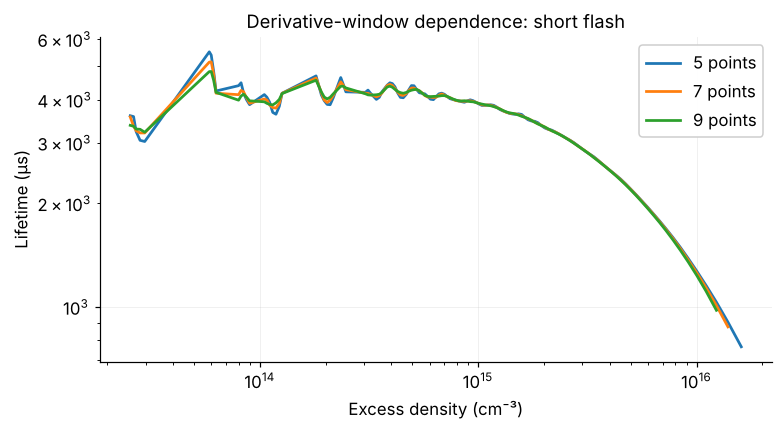

In [22]:
fig = lh.plot_smoothing(short_measurement)
plt.show()

*Figure 9. Real short-flash data reconstructed with three derivative windows. The same raw data can yield different early-time lifetimes, so a smooth-looking trace alone is not a validity test.*

### 11.3 Determine the optical constant from trustworthy overlap

If short- and full-flash measurements probe the same stable sample at the same temperature and injection, they should agree after appropriate analysis. On an interval where the short flash is genuinely transient, vary the full-flash optical constant and minimise

$$\mathcal L(C_{\mathrm{opt}})=\frac{1}{M}\sum_j
\left[\log_{10}\tau_{\mathrm{gen}}(\Delta n_j;C_{\mathrm{opt}})
-\log_{10}\tau_{\mathrm{tr}}(\Delta n_j)\right]^2.\tag{55}$$

The grid is equally spaced in $\log\Delta n$ over a **fixed** valid overlap, giving comparable weight across injection decades. Interpolation is log–log and never extrapolates outside either measured curve. We require at least five measured points from each trace within the window. The short-flash reference check uses its stated $C_{\mathrm{opt}}$; uncertainty in that scale also affects the residual-generation test.

Two filters serve different purposes. **Filter 1** rejects short-flash points with appreciable residual generation. **Filter 2** restricts the common injection interval to the region supported by signal quality and artefact checks. A low-injection upturn is not automatically a reason to trim data: record the diagnostic evidence and show the excluded region. The 2–7 × 10$^{15}$ cm$^{-3}$ interval below is an explicit teaching choice, not an automatically validated universal range.

Conditional fitted Copt: 1.0778
RMS mismatch: 0.0021 log10 decades
Actual fit interval (cm⁻³): (2000000000000000.0, 7000000000000000.0)


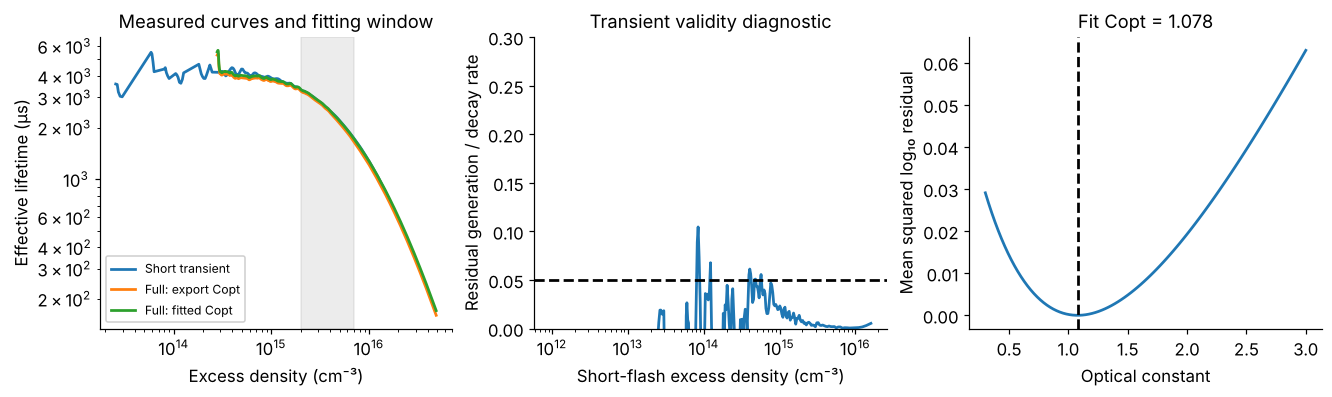

In [23]:
optical = lh.fit_optical_constant(short, full, injection_range=(2e15, 7e15),
                                  max_transient_error=0.05)
print(f"Conditional fitted Copt: {optical['C_opt']:.4f}")
print(f"RMS mismatch: {optical['rms_decades']:.4f} log10 decades")
print('Actual fit interval (cm⁻³):', optical['injection_range'])
fig = lh.plot_optical_fit(short, full, optical)
plt.show()

*Figure 10. Measured curves, a transient-validity diagnostic and the optical objective. The shaded interval is the fitting interval; the full curves remain visible so disagreement elsewhere is not concealed.*

For this implementation the fitted scale is approximately 1.078, compared with 1.15 stored in the full-flash export. This is a **conditional reanalysis** using the stated reference gain, no-BGN statistics, included mobility implementation and a five-point derivative. A small matching residual does not validate those assumptions, establish sample identity or supply an uncertainty on $C_{\mathrm{opt}}$. Repeat the analysis for reasonable windows and derivative settings. A shape mismatch cannot generally be repaired by a single optical scale.

## 12. Artefacts that make a lifetime curve misleading

### 12.1 Trapping at low injection

A trap can hold a minority carrier while its compensating majority carrier remains mobile. Charge neutrality then involves trapped charge as well as free electrons and holes; $\Delta n=\Delta p$ for the free populations need not hold. The coil counts the extra mobile conductance, but the paired-carrier inversion assigns it to freely recombining pairs. An apparent lifetime enhancement or slow tail can result. Trapping is not the same as an SRH centre completing a recombination cycle: trapping can delay release without immediately removing a pair [[22]](#ref22).

A useful schematic description is

$$\Delta\Sigma_{\mathrm{meas}}=\Delta\Sigma_{\mathrm{pairs}}+
\Delta\Sigma_{\mathrm{extra}},\qquad
\Delta n_{\mathrm{app}}\simeq\Delta n+
\frac{\Delta\Sigma_{\mathrm{extra}}}{qW(\mu_n+\mu_p)}.\tag{56}$$

The second expression assumes constant mobilities only to illustrate the error. It is not a trap correction formula for an arbitrary sample. Repeat after controlled illumination history and with different pulse durations or bias light. Bias light can change trap occupancy, but it also changes the operating injection and can produce a differential measurement. Subtracting a constant tail is not generally justified; compare PC with an independent recombination-sensitive measurement such as PL under matched conditions.

### 12.2 Depletion-region modulation

A charged surface or junction can deplete majority carriers from a finite depth in the dark. Illumination can reduce the band bending or shrink that region, restoring mobile majority carriers to conduction. Some conductance change now comes from a **change in conducting volume**, rather than uniform pair injection. A paired-carrier inversion can consequently overestimate low-injection lifetime [[23]](#ref23).

Trapping and depletion modulation can look similar in a lifetime plot but have different origins. Look for sensitivity to surface charge, junction structure, passivation and bias illumination; compare PC and PL where available. A bias-dependent tail is evidence to investigate, not proof of a unique mechanism. Genuine injection-dependent SRH or surface recombination can also raise lifetime toward low injection. Neither an upward curve nor a high numerical lifetime identifies an artefact by itself.

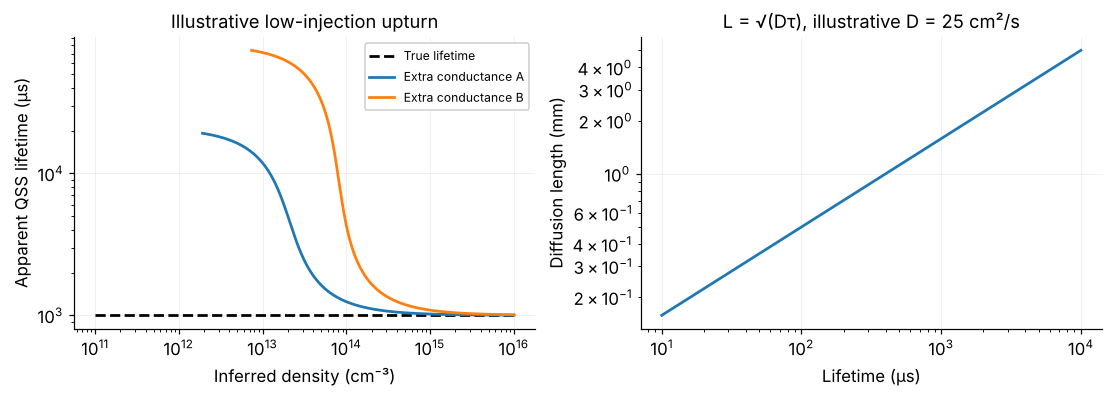

In [24]:
fig = lh.plot_artefacts()
plt.show()

*Figure 11. Left: explicitly synthetic extra-conductance examples with a true 1 ms QSS lifetime. These are phenomenological illustrations, not trap-kinetic or depletion-width fits. Right: an illustrative diffusion length showing why long-lifetime samples can be sensitive to edges well beyond the coil footprint.*

### 12.3 Sample size, edges and spatial uniformity

The coil has a lateral weighting function, not a perfectly sharp circular footprint. A sample must cover the calibrated sensitive region with margin, and the illuminated area must cover the region from which carriers contribute to the measurement. A reported radius near 2 cm in one WCT-120 study [[20]](#ref20) does **not** establish that a 2 × 2 cm square is adequate for a WCT-120TS. The manufacturer's standard-configuration product note instead lists 60–150 mm sample diameter [[21]](#ref21). Small coupons need geometry-specific validation or an appropriate small-sample arrangement.

Lateral transport adds another length scale:

$$L_D=\sqrt{D\tau_{\mathrm{eff}}}.\tag{57}$$

This is an order-of-magnitude diffusion length, not a universal edge-distance rule. Cut edges can draw carriers from the sensed region and lower the observed lifetime, particularly for long lifetimes. Translate and rotate the sample, compare central and near-edge positions, and compare different sample sizes or edge treatments while controlling lift-off. Spatially resolved PL can reveal edge damage, scratches, poor passivation and nonuniform regions that a single coil-weighted number hides.

PL intensity is itself affected by excitation and optical properties. A dark PL region is a prompt for investigation, not automatically a calibrated lifetime map. Keep exposure, excitation and processing comparable. No PL images are included, so this notebook gives the diagnostic procedure without fabricating a measured image.

### 12.4 Handling and other acquisition problems

Handling scratches, local contamination and damaged passivation can introduce real recombination. They are not merely electronic noise. Handle outside the sensed region, inspect before and after, repeat with consistent placement, and distinguish a stable low-lifetime region from changing measurement geometry. A particle under the wafer also changes lift-off and may produce a conductance-calibration error.

| Observation | Possible cause | Useful check |
|---|---|---|
| Low-injection lifetime upturn | Trapping, depletion modulation, offset, or genuine recombination dependence | Bias/history study, surface comparison, matched PC/PL |
| Early short-flash lifetime too high | Residual generation or derivative distortion | Plot $G/(-d\Delta n/dt)$; vary the derivative window |
| Lifetime moves with reference aperture | Incorrect gain, saturation or mismatch | Correct aperture-specific calibration; inspect reference waveform |
| Density shifts with placement or spacer | Coil weighting, lift-off or sample coverage | Repeat controlled placement; use appropriate calibration geometry |
| Negative recombination or bulk lifetime | Baseline/timing/model mismatch or over-subtracted intrinsic loss | Inspect raw signals and assumptions; do not report a negative physical lifetime |
| Repeated flashes progressively change the curve | Heating, light-induced changes or trap occupancy | Track temperature and illumination history |
| Smooth curve but strong position dependence | Spatial nonuniformity or edge recombination | PL imaging and a position series |

The embedded exports contain negative **estimated bulk lifetimes**, although their effective lifetimes are positive. That does not describe a negative physical recombination time. It flags inconsistency in the model-based subtraction or inputs used by the instrument software. Black and Macdonald's Auger study emphasises the difficulty of separating surface and intrinsic contributions in precisely calibrated high-lifetime measurements [[24]](#ref24); a new intrinsic coefficient should not be inferred from these two traces alone.

## 13. Processing and reporting a measurement, and testing the analysis

The loader returns metadata and the numerical time series separately. `analyse_measurement` uses the exported excess conductance route; `voltage_to_sheet` provides the separate raw-voltage route when the matching air zero and coil coefficients are known. Choose a single route and state it. The original files are never modified.

In [25]:
# Replace the embedded examples with your own exports when needed:
# short_measurement = lh.load_sinton('my_short_flash.txt')
# full_measurement = lh.load_sinton('my_full_flash.txt')

full_calibrated = lh.analyse_measurement(full_measurement, C_opt=optical['C_opt'],
                                        ref_V_per_sun=0.0113756, window=5)
target_dn = 5e15
tau_short = lh.lifetime_at_injection(short, target_dn,
                                    extra_mask=short['transient_error'] <= 0.05)
tau_full = lh.lifetime_at_injection(full_calibrated, target_dn)
wafer = lh.Sample(doping=full_calibrated['doping'], kind='n', T=full_calibrated['T_K'],
                  W_um=full_calibrated['W_cm'] * 1e4)
print(f'At Δn = {target_dn:.2e} cm⁻³:')
print(f'  Short-flash transient: {tau_short * 1e6:.1f} µs')
print(f'  Full-flash generalised, fitted Copt: {tau_full * 1e6:.1f} µs')
print(f"  Full-flash temperature: {full_calibrated['T_K']:.2f} K")
print(f"  Thickness: {full_calibrated['W_cm'] * 1e4:.0f} µm")
print(f"  Conditional implied voltage at this injection: {lh.implied_voltage(target_dn, wafer):.4f} V")

At Δn = 5.00e+15 cm⁻³:
  Short-flash transient: 2197.5 µs
  Full-flash generalised, fitted Copt: 2190.1 µs
  Full-flash temperature: 300.68 K
  Thickness: 200 µm
  Conditional implied voltage at this injection: 0.6982 V


The reconstructed short-flash lifetime at $5\times10^{15}$ cm$^{-3}$ is about 2.20 ms, rather than the approximately 1.90 ms summary stored by the original software. This is a transparent reanalysis with different mobility/statistics and derivative choices, not a claim that the original instrument result is wrong. The calibrated full-flash result is matched in the specified overlap by construction. Agreement after fitting is therefore not independent validation.

$5\times10^{15}$ cm$^{-3}$ is the reporting density chosen in these files; it is not a universal one-sun operating condition. Eq. (43) gives the implied voltage at a specified density. To call it **one-sun implied $V_{oc}$**, first solve Eq. (44) for the density at the calibrated one-sun generation rate. A contactless implied voltage is also distinct from terminal device $V_{oc}$.

### 13.1 Contents of a reported result

Report the sample identity, type, thickness, temperature, preparation and surface state; the stated injection at which lifetime is quoted; flash and analysis modes; reference aperture and gain; optical constant and how it was determined; coil calibration convention and date; mobility and carrier-statistics model; derivative settings; and the accepted injection interval. Include repeatability, placement dependence and a description of excluded points.

An uncertainty budget should separate random noise and repeatability from common scale errors in conductance, mobility, thickness and generation. A dense interpolation grid does not create more independent measurements. Derivative filtering correlates neighbouring points, and mode matching shares calibration assumptions. The objective RMS is a curve-matching diagnostic, not a confidence interval. The present package includes diagnostic sensitivity checks but does not assign a traceable combined uncertainty without the missing calibration-standard uncertainties and repeat measurements.

### 13.2 Recovering a known lifetime

The real exports have no known answer. To test the analysis chain we need data whose true lifetime is known and whose imperfections we control. `synthetic_flash` integrates the carrier balance, Eq. (4), for a chosen lifetime curve $\tau(\Delta n)$ and an exponentially decaying flash. It then adds noise to the density. We use the effective-lifetime curve of the Section 6 model wafer as the truth. Each mode gets a flash that suits it, because each mode is valid only when its own assumption holds:

| Mode | Flash | Why |
|---|---|---|
| Generalised, Eq. (52) | Decay time of 2 ms, comparable to $\tau$ | Storage and generation are both kept |
| QSS, Eq. (53) | Decay time of 30 ms, much longer than $\tau$ | Storage is small |
| Transient, Eq. (54) | Decay time of 30 µs, much shorter than $\tau$ | Generation is negligible after the flash |

The analysis sees only the noisy $\Delta n(t)$ and $G(t)$, as it would with a real instrument. The noise is 0.3% of the signal plus a small additive floor. QSS and transient points are kept only where the measured error ratios $\epsilon_{\mathrm{QSS}}$ and $\epsilon_{\mathrm{tr}}$ are at most 5%.

In [26]:
base = lh.Sample(doping=3e15, kind='n', T=300.0, W_um=150.0, S_front=10.0, S_rear=10.0)

def tau_true(dn):
    """True effective lifetime (s) of the model wafer in Section 6."""
    return float(lh.component_lifetimes(dn, base)['effective'])

flashes = {
    'generalized': dict(G0=1e19, flash_s=2e-3,  t_end_s=12e-3,  n_points=1201),
    'qss':         dict(G0=4e18, flash_s=30e-3, t_end_s=120e-3, n_points=2401),
    'transient':   dict(G0=1e20, flash_s=30e-6, t_end_s=6e-3,   n_points=1201),
}
recovered = {}
for mode, flash in flashes.items():
    syn = lh.synthetic_flash(tau_true, noise=0.003, **flash)
    res = lh.lifetime_from_signals(syn['time'], syn['dn'], syn['G'], mode, window=21)
    keep = {'qss': res['qss_error'] <= 0.05,
            'transient': res['transient_error'] <= 0.05}.get(mode)
    recovered[mode] = (syn, res, keep)

print('mode          dn (cm^-3)   true (µs)   recovered (µs)   error')
for mode, (syn, res, keep) in recovered.items():
    for dn in (3e14, 1e15, 2e15):
        est = lh.lifetime_at_injection(res, dn, extra_mask=keep)
        true = tau_true(dn)
        print(f'{mode:<12}  {dn:9.1e}  {true * 1e6:9.1f}  {est * 1e6:14.1f}  {100 * (est / true - 1):+6.1f}%')

mode          dn (cm^-3)   true (µs)   recovered (µs)   error
generalized     3.0e+14      671.9           667.1    -0.7%
generalized     1.0e+15      668.1           663.5    -0.7%
generalized     2.0e+15      660.2           654.6    -0.9%
qss             3.0e+14      671.9           686.0    +2.1%
qss             1.0e+15      668.1           682.5    +2.2%
qss             2.0e+15      660.2           675.4    +2.3%
transient       3.0e+14      671.9           647.0    -3.7%
transient       1.0e+15      668.1           672.2    +0.6%
transient       2.0e+15      660.2           655.7    -0.7%


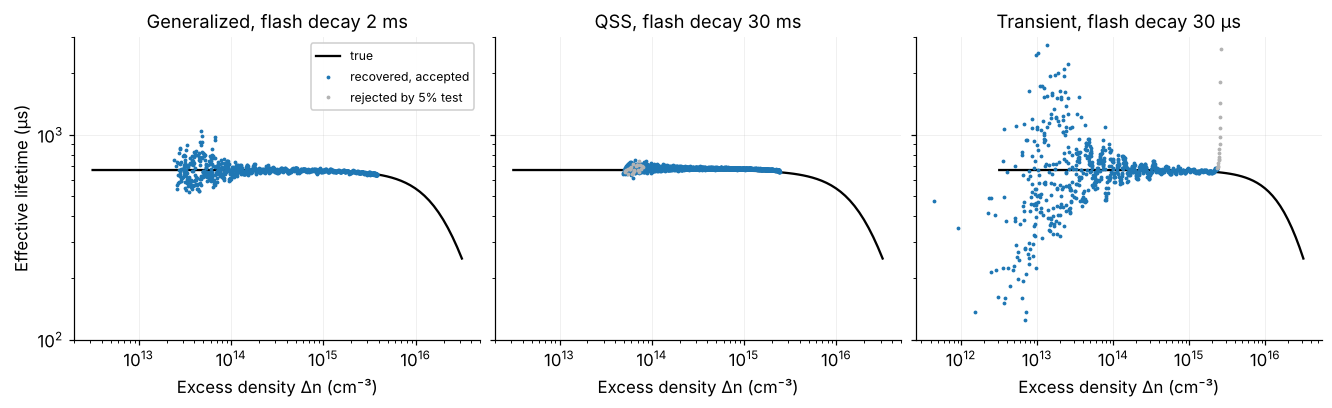

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True, constrained_layout=True)
grid = np.logspace(12.5, 16.5, 80)
for ax, (mode, (syn, res, keep)) in zip(axes, recovered.items()):
    ok = res['valid'] if keep is None else res['valid'] & keep
    rejected = res['valid'] & ~ok
    ax.loglog(grid, [tau_true(x) * 1e6 for x in grid], 'k', lw=1.5, label='true')
    ax.loglog(res['dn'][ok], res['tau'][ok] * 1e6, '.', ms=3, label='recovered, accepted')
    ax.loglog(res['dn'][rejected], res['tau'][rejected] * 1e6, '.', ms=3, color='0.7',
              label='rejected by 5% test')
    tf = flashes[mode]['flash_s']
    tf_label = f'{tf * 1e3:g} ms' if tf >= 1e-3 else f'{tf * 1e6:g} µs'
    ax.set(title=f"{ {'qss': 'QSS'}.get(mode, mode.capitalize()) }, flash decay {tf_label}",
           xlabel='Excess density Δn (cm⁻³)', ylim=(1e2, 3e3))
    ax.grid(alpha=0.2)
axes[0].set_ylabel('Effective lifetime (µs)')
axes[0].legend(fontsize=8)
plt.show()

*Figure 12. Recovery of a known lifetime curve (black) from synthetic noisy signals by the three analysis modes. Grey points fail the 5% validity test of their mode and are not used.*

In [28]:
# A deliberate defect: the generation scale is wrong by ±10%
# (as it would be with a wrong optical constant or reference gain).
syn, res, keep = recovered['generalized']
true = tau_true(1e15)
for scale in (0.9, 1.0, 1.1):
    bad = lh.lifetime_from_signals(syn['time'], syn['dn'], scale * syn['G'], 'generalized', window=21)
    est = lh.lifetime_at_injection(bad, 1e15)
    print(f'generation x{scale:.1f}: τ(Δn = 1e15 cm⁻³) = {est * 1e6:6.1f} µs  ({100 * (est / true - 1):+.1f}% from true)')

generation x0.9: τ(Δn = 1e15 cm⁻³) =  711.5 µs  (+6.5% from true)
generation x1.0: τ(Δn = 1e15 cm⁻³) =  663.5 µs  (-0.7% from true)
generation x1.1: τ(Δn = 1e15 cm⁻³) =  621.6 µs  (-7.0% from true)


Each mode recovers the true lifetime inside its own validity window, with errors of 1–4%. The generalised mode is the most accurate (under 1%) because it keeps both storage and generation. QSS overestimates the lifetime by about 2%, as expected when storage is neglected. The error is $\epsilon_{\mathrm{QSS}}$, Eq. (53), which the 5% test bounds. The transient mode is the noisiest (−3.7% at $3\times10^{14}$ $\mathrm{cm}^{-3}$), because $d\Delta n/dt$ is small and noisy at low density.

The last cell adds a deliberate defect. A 10% error in the generation scale moves the generalised lifetime by about 7% in the opposite direction. The shift is smaller than 10% because Eq. (52) uses the difference $G-d\Delta n/dt$, and $d\Delta n/dt$ is obtained from $\Delta n$ alone. A scale error of this size is what a wrong optical constant or reference gain produces. Eq. (54) contains no $G$, so the transient mode does not carry this error once generation is negligible. This is why Section 11.3 uses the short-flash transient lifetime to fix $C_{\mathrm{opt}}$.

The decay branch covers only the densities the flash reached, up to about $4\times10^{15}$ $\mathrm{cm}^{-3}$ here, so the high-injection fall of the true curve is not tested.

This test checks the numerical chain: differentiation, mode selection and validity tests. It cannot check the calibration or the instrument (Section 14).

## 14. Assumptions, limitations and scope

This notebook teaches shapes and trends. It is **not** a certified analysis and must not be used for quantitative device work or reporting without the instrument manufacturer's calibration and analysis.

**Physics (Sections 1–8)**

- The wafer is uniform, quasi-neutral and one-dimensional, with equal excess electron and hole densities, Eq. (1).
- Dopants are fully ionised, statistics are nondegenerate and bandgap narrowing is off. Incomplete ionisation and Schenk narrowing are given as extensions (Section 4.5), not used in the examples.
- The teaching model covers 275–363 K and uses constant material parameters.
- Bulk SRH uses one generic deep level with specified capture times. Real wafers have several defects.
- The combined curves in Sections 6 and 7 use a fixed $S_{\mathrm{eff}}$. The interface-state example prescribes the surface potential. The full gate and charge solver, Eq. (23), is not implemented.
- Photon recycling is set to zero in the combined curves. The recycling integral, Eq. (14), needs optical arrays that the notebook does not supply.
- These curves are forward calculations. A measured lifetime curve cannot be inverted uniquely into bulk and surface contributions.

**Measurement (Sections 9–13)**

- The coil calibration is empirical and valid only over the range of its standards. The held-out stacks show an error of about 4%. A 200 µm sample is thinner than the thinnest standard, so the thickness correction is an extrapolation.
- The reference gain is carried over from earlier analysis and is not recorded in the exports. $C_{\mathrm{opt}}$ is fitted conditionally on that gain, the mobility model and the derivative settings.
- The embedded exports are two examples of one wafer. They are not a validation of the analysis, and the coil calibration is not applied to them.
- Mobilities come from a Klaassen implementation that is not independently validated here. Doping is inferred from dark resistivity using that model.
- Trapping and depletion-region modulation are described and illustrated phenomenologically. No correction is implemented.
- The known-answer test in Section 13.2 uses the same carrier balance as the analysis. It checks the numerical chain (differentiation, mode selection, validity tests). It does not test the physics assumptions, the calibration or the instrument.
- No traceable uncertainty is assigned. The fitted $C_{\mathrm{opt}}$ residual is a curve-matching diagnostic, not a confidence interval.

**Not covered:** photoluminescence lifetime, transient microwave methods, spatially resolved lifetime, finished-cell $V_{oc}$ and lifetime spectroscopy for defect identification.

<a id="references"></a>

## References

Each entry is linked from the theory and model sections. Equation numbers in helper docstrings refer to **this notebook**, not to the original paper.

<a id="ref1"></a>
**[1]** S. M. Sze and K. K. Ng, *Physics of Semiconductor Devices*, 3rd ed., Wiley (2007). [doi:10.1002/0470068329](https://doi.org/10.1002/0470068329).

<a id="ref2"></a>
**[2]** H. Nagel, C. Berge and A. G. Aberle, “Generalized analysis of quasi-steady-state and quasi-transient measurements of carrier lifetimes in semiconductors”, *J. Appl. Phys.* **86**, 6218–6221 (1999). [doi:10.1063/1.371633](https://doi.org/10.1063/1.371633).

<a id="ref3"></a>
**[3]** W. Shockley and W. T. Read Jr., “Statistics of the recombinations of holes and electrons”, *Phys. Rev.* **87**, 835–842 (1952). [doi:10.1103/PhysRev.87.835](https://doi.org/10.1103/PhysRev.87.835).

<a id="ref4"></a>
**[4]** R. N. Hall, “Electron-hole recombination in germanium”, *Phys. Rev.* **87**, 387 (1952). [doi:10.1103/PhysRev.87.387](https://doi.org/10.1103/PhysRev.87.387).

<a id="ref5"></a>
**[5]** H. T. Nguyen, S. C. Baker-Finch and D. Macdonald, “Temperature dependence of the radiative recombination coefficient in crystalline silicon from spectral photoluminescence”, *Appl. Phys. Lett.* **104**, 112105 (2014). [doi:10.1063/1.4869295](https://doi.org/10.1063/1.4869295).

<a id="ref6"></a>
**[6]** A. Fell et al., “Radiative recombination in silicon photovoltaics: Modeling the influence of charge carrier densities and photon recycling”, *Sol. Energy Mater. Sol. Cells* **230**, 111198 (2021). [doi:10.1016/j.solmat.2021.111198](https://doi.org/10.1016/j.solmat.2021.111198).

<a id="ref7"></a>
**[7]** T. Niewelt et al., “Reassessment of the intrinsic bulk recombination in crystalline silicon”, *Sol. Energy Mater. Sol. Cells* **235**, 111467 (2022). [doi:10.1016/j.solmat.2021.111467](https://doi.org/10.1016/j.solmat.2021.111467).

<a id="ref8"></a>
**[8]** L. E. Black, Y. Zhu, Z. Hameiri and D. H. Macdonald, “Temperature dependence of Auger recombination in crystalline silicon from 117–463 K”, *Sol. Energy Mater. Sol. Cells* **295**, 113985 (2026). [doi:10.1016/j.solmat.2025.113985](https://doi.org/10.1016/j.solmat.2025.113985).

<a id="ref9"></a>
**[9]** K. R. McIntosh and L. E. Black, “On effective surface recombination parameters”, *J. Appl. Phys.* **116**, 014503 (2014). [doi:10.1063/1.4886595](https://doi.org/10.1063/1.4886595).

<a id="ref10"></a>
**[10]** Sinton Instruments, [Lifetime tester FAQs](https://www.sintoninstruments.com/faqs/), accessed 24 September 2026. Manufacturer guidance on reported injection and measurement interpretation.

<a id="ref11"></a>
**[11]** A. Cuevas and R. A. Sinton, “Prediction of the open-circuit voltage of solar cells from the steady-state photoconductance”, *Prog. Photovolt.* **5**, 79–90 (1997). [doi:10.1002/(SICI)1099-159X(199703/04)5:2<79::AID-PIP155>3.0.CO;2-J](https://doi.org/10.1002/(SICI)1099-159X(199703/04)5:2%3C79::AID-PIP155%3E3.0.CO;2-J).

<a id="ref12"></a>
**[12]** R. Pässler, “Dispersion-related description of temperature dependencies of band gaps in semiconductors”, *Phys. Rev. B* **66**, 085201 (2002). [doi:10.1103/PhysRevB.66.085201](https://doi.org/10.1103/PhysRevB.66.085201).

<a id="ref13"></a>
**[13]** R. Couderc, M. Amara and M. Lemiti, “Reassessment of the intrinsic carrier density temperature dependence in crystalline silicon”, *J. Appl. Phys.* **115**, 093705 (2014). [doi:10.1063/1.4867776](https://doi.org/10.1063/1.4867776).

<a id="ref14"></a>
**[14]** P. P. Altermatt et al., “Injection dependence of spontaneous radiative recombination in c-Si: experiment, theoretical analysis, and simulation”, *NUSOD 2005*, 47–48. [doi:10.1109/NUSOD.2005.1517014](https://doi.org/10.1109/NUSOD.2005.1517014).

<a id="ref15"></a>
**[15]** C. Schinke et al., “Uncertainty analysis for the coefficient of band-to-band absorption of crystalline silicon”, *AIP Advances* **5**, 067168 (2015). [doi:10.1063/1.4923379](https://doi.org/10.1063/1.4923379).

<a id="ref16"></a>
**[16]** S. C. Baker-Finch et al., “Near-infrared free carrier absorption in heavily doped silicon”, *J. Appl. Phys.* **116**, 063106 (2014). [doi:10.1063/1.4893176](https://doi.org/10.1063/1.4893176).

<a id="ref17"></a>
**[17]** A. Schenk, “Finite-temperature full random-phase approximation model of band gap narrowing for silicon device simulation”, *J. Appl. Phys.* **84**, 3684–3695 (1998). [doi:10.1063/1.368545](https://doi.org/10.1063/1.368545).

<a id="ref18"></a>
**[18]** R. S. Bonilla and P. R. Wilshaw, “On the c-Si/SiO₂ interface recombination parameters from photo-conductance decay measurements”, *J. Appl. Phys.* **121**, 135301 (2017). [doi:10.1063/1.4979722](https://doi.org/10.1063/1.4979722).

<a id="ref19"></a>
**[19]** R. S. Bonilla et al., “Charge fluctuations at the Si–SiO₂ interface and its effect on surface recombination in solar cells”, *Sol. Energy Mater. Sol. Cells* **215**, 110649 (2020). [doi:10.1016/j.solmat.2020.110649](https://doi.org/10.1016/j.solmat.2020.110649).

<a id="ref20"></a>
**[20]** L. E. Black and D. H. Macdonald, “Accounting for the dependence of coil sensitivity on sample thickness and lift-off in inductively coupled photoconductance measurements”, *IEEE J. Photovolt.* **9**, 1563–1574 (2019). [doi:10.1109/JPHOTOV.2019.2942484](https://doi.org/10.1109/JPHOTOV.2019.2942484).

<a id="ref21"></a>
**[21]** Sinton Instruments, [WCT-120TS product note](https://www.sintoninstruments.com/wp-content/uploads/WCT-120-TS-product-note.pdf), PNV021722. Standard-configuration sample dimensions and measurement modes; not a small-coupon calibration.

<a id="ref22"></a>
**[22]** D. Macdonald, R. A. Sinton and A. Cuevas, “On the use of a bias-light correction for trapping effects in photoconductance-based lifetime measurements of silicon”, *J. Appl. Phys.* **89**, 2772–2778 (2001).

<a id="ref23"></a>
**[23]** M.-U. Halbich and J. Schmidt, “Extraction of PEDOT:PSS/c-Si junction properties by modeling of injection-dependent lifetime measurements including depletion region modulation”, *Phys. Status Solidi RRL* **15**, 2100008 (2021). [doi:10.1002/pssr.202100008](https://doi.org/10.1002/pssr.202100008).

<a id="ref24"></a>
**[24]** L. E. Black and D. H. Macdonald, “On the quantification of Auger recombination in crystalline silicon”, *Sol. Energy Mater. Sol. Cells* **234**, 111428 (2022). [doi:10.1016/j.solmat.2021.111428](https://doi.org/10.1016/j.solmat.2021.111428).

<a id="ref25"></a>
**[25]** D. B. M. Klaassen, “A unified mobility model for device simulation—I. Model equations and concentration dependence”, *Solid-State Electron.* **35**, 953–959 (1992). [doi:10.1016/0038-1101(92)90325-7](https://doi.org/10.1016/0038-1101(92)90325-7). The helper's parameter set follows the DEVSIM implementation of this model.

## Summary of equations

One sequence covers the whole notebook. The equation numbers match the helper docstrings.

| Equation | Abbreviated form | Meaning | Source / derivation |
|---|---|---|---|
| 1 | $n=n_0+\Delta n;\ p=p_0+\Delta n$ | Injected carrier populations | [[1]](#ref1) |
| 2 | $p_0-n_0=N_A-N_D,\qquad n_0p_0=n_i^2$ | Equilibrium charge neutrality and mass action | [[1]](#ref1) |
| 3 | $n_{\mathrm{maj,0}}=(N+\sqrt{N^2+4n_i^2})/2$ | Stable equilibrium population solution | [[1]](#ref1) |
| 4 | $d\Delta n/dt=G-U_{\mathrm{eff}}$ | Generation, recombination and storage | [[1]](#ref1)[[2]](#ref2) |
| 5 | $\tau_{\mathrm{eff}}=\Delta n/(G-d\Delta n/dt)$ | Effective recombination lifetime | [[1]](#ref1)[[2]](#ref2) |
| 6 | $G=U_{\mathrm{eff}}=\Delta n/\tau_{\mathrm{eff}}$ | Steady generation–recombination balance | [[1]](#ref1) |
| 7 | $\Delta n=G_0\tau(1-e^{-t/\tau})$ during illumination | Constant-lifetime pulse response | [[1]](#ref1) |
| 8 | $U_{\mathrm{SRH}}=\frac{np-n_i^2}{\tau_{p0}(n+n_1)+\tau_{n0}(p+p_1)}$ | Single-level SRH net rate | [[3]](#ref3)[[4]](#ref4) |
| 9 | $\tau_{j0}=1/(N_t\sigma_jv_{th,j})$ | Trap capture parameters; mean thermal speed | [[1]](#ref1)[[3]](#ref3)[[4]](#ref4) |
| 10 | $n_1=n_i e^{\varepsilon_t/(k_BT)},\qquad p_1=n_i e^{-\varepsilon_t/(k_BT)},\qquad n_1p_1=n_i^2$ | SRH auxiliary populations | [[1]](#ref1)[[3]](#ref3)[[4]](#ref4) |
| 11 | $U_{\mathrm{rad,net}}=(1-f_{\mathrm{PR}})B(np-n_i^2)$ | Net radiative loss with a specified recycling fraction | [[5]](#ref5)[[6]](#ref6) |
| 12 | $\log_{10}(B_{\mathrm{low}}/[\mathrm{cm}^{3}\,\mathrm{s}^{-1}])=\sum_{k=0}^{5}a_kT^k$ | Nguyen low-density radiative coefficient; T in K | [[5]](#ref5) |
| 13 | $B_{\mathrm{rel}}=b_{\mathrm{min}}+(1-b_{\mathrm{min}})/[1+(N_\Sigma/b_1)^{.54}+(N_\Sigma/b_3)^{1.25}]$ | Altermatt-type density correction | [[14]](#ref14) |
| 14 | $B_{\mathrm{net}}=B_{\mathrm{low}}B_{\mathrm{rel}}(1-f_{\mathrm{PR}})$ | Photon recycling and net radiative coefficient | [[6]](#ref6) |
| 15 | $\alpha_{bb}(T)=\alpha_{bb}(295)(T/295)^{295c_T}$ | Absorption temperature scaling and separate absorption channels | [[15]](#ref15) |
| 16 | $\alpha_{\mathrm{FCA}}=CN\lambda^c$ | Doped-region FCA fits; λ in cm, N in cm⁻³, α in cm⁻¹ | [[16]](#ref16) |
| 17 | $U_{\mathrm{Aug}}=C_n(n^2p-n_0^2p_0)+C_p(np^2-n_0p_0^2)$ | Auger rate with equilibrium subtraction | [[7]](#ref7)[[8]](#ref8) |
| 18 | $C_n^{scr}=C_{n,d}^0e^{-E_a/k_BT}+C_{n,ph}^0\coth(E_{ph,n}/2k_BT)$ | Screened direct and phonon-assisted Auger coefficients | [[8]](#ref8) |
| 19 | $C_j=C_j^{scr}\{1+(g_{j,max}-1)/(1+[(n+p)/N_{\mathrm{ref}}]^2)\}$ | Density and temperature dependence of Coulomb enhancement | [[8]](#ref8) |
| 20 | $D_{\mathrm{it}}(E):\ \text{Gaussian, tophat or exponential tail}$ | Gaussian, tophat and exponential-tail Dit shapes | [[18]](#ref18) |
| 21 | $U_s=\sum_a\int D_{\mathrm{it},a}(E)\,u_a(E)\,dE$, with $u_a$ the rate per state in Eq. (21) | Interface occupation and integrated SRH flux | [[18]](#ref18) |
| 22 | $n_s=n_b e^{q\psi_s/k_BT},\quad p_s=p_b e^{-q\psi_s/k_BT}$ | Surface carrier populations under band bending | [[1]](#ref1)[[18]](#ref18) |
| 23 | $Q_{\mathrm{Si}}+Q_{\mathrm{it}}+Q_f+Q_{\mathrm{ext}}+Q_{\mathrm{gate}}=0$ | Surface charge balance and a uniform-base Poisson expression | [[1]](#ref1)[[18]](#ref18) |
| 24 | $\langle U_s\rangle=\int U_s(Q)w(Q)dQ/\int w(Q)dQ$ | Normalised charge-fluctuation average | [[19]](#ref19) |
| 25 | $J_{0s}=qU_s/(n_bp_b/n_i^2-1)$ | Surface saturation-current parameter at a stated injection | [[9]](#ref9) |
| 26 | $E_g^0(T)$ from the Pässler polynomial $P(x)$ | Pässler temperature-dependent Si bandgap | [[12]](#ref12) |
| 27 | $n_i^0=1.541\times10^{15}T^{1.712}e^{-E_g^0/(2k_BT)}$ | Couderc intrinsic-density parameterisation | [[13]](#ref13) |
| 28 | $\nu=n a_X^3,\quad F=k_BT/R_X$ | Dimensionless Schenk inputs | [[17]](#ref17) |
| 29 | $\delta_{xc,j}=-\mathcal N_{xc,j}/\mathcal D_{xc,j}$ | Schenk exchange/correlation approximation | [[17]](#ref17) |
| 30 | $\delta_{I,j}\ \text{as expanded above}$ | Schenk ionic contribution | [[17]](#ref17) |
| 31 | $\Delta E_g=-R_X\sum_j(\delta_{xc,j}+\delta_{I,j})$ | Gap reduction and the effective-ni approximation | [[17]](#ref17) |
| 32 | $p+N_D^+=n+N_A^-$ | Shallow-dopant occupation and charge neutrality | [[1]](#ref1) |
| 33 | $\overline U_{\mathrm{eff}}=\overline U_{\mathrm{bulk}}+(U_{s,f}+U_{s,r})/W$ | Bulk and two surface losses per wafer volume | [[1]](#ref1)[[9]](#ref9) |
| 34 | $S_{\mathrm{eff},f}=\frac{U_{s,f}}{\Delta n},\qquad S_{\mathrm{eff},r}=\frac{U_{s,r}}{\Delta n}$ | Effective velocity referenced to bulk excess density | [[9]](#ref9) |
| 35 | $1/\tau_{\mathrm{eff}}=1/\tau_{\mathrm{bulk}}+(S_{\mathrm{eff},f}+S_{\mathrm{eff},r})/W$ | Uniform-density surface lifetime | [[9]](#ref9) |
| 36 | $1/\tau_{\mathrm{bulk}}=1/\tau_{SRH}+1/\tau_{\mathrm{rad,net}}+1/\tau_{\mathrm{Aug}}$ | Independent bulk recombination channels | [[1]](#ref1) |
| 37 | $1/\tau_{\mathrm{eff}}=\sum_{j=1}^4 1/\tau_j$ | Four-channel effective lifetime | [[1]](#ref1)[[9]](#ref9) |
| 38 | $\frac{1}{\tau_{\mathrm{intr}}}=\frac{1}{\tau_{\mathrm{rad,net}}}+\frac{1}{\tau_{\mathrm{Aug}}}$ | Intrinsic lifetime for the stated model and optical conditions | [[7]](#ref7)[[8]](#ref8) |
| 39 | $m_j=\frac{d\ln U_j}{d\ln\Delta n},\qquad \frac{d\ln\tau_j}{d\ln\Delta n}=1-m_j$ | Local recombination order and lifetime slope | From lifetime definition |
| 40 | $\tau_{\mathrm{rad,net}}=1/[B_{\mathrm{net}}(n_0+p_0+\Delta n)]$ | Radiative low/high injection limits at fixed coefficient | [[1]](#ref1)[[5]](#ref5) |
| 41 | $U_{\mathrm{Aug}}\propto\Delta n^3;\ \tau_{\mathrm{Aug}}\propto\Delta n^{-2}$ | Constant-coefficient high-injection Auger limit | [[1]](#ref1)[[8]](#ref8) |
| 42 | Low: $\tau_{n0}$ (p-type), $\tau_{p0}$ (n-type); high: $\tau_{n0}+\tau_{p0}$ | Deep-level SRH low/high injection limits | [[3]](#ref3)[[4]](#ref4) |
| 43 | $V_{\mathrm{imp}}=(k_BT/q)\ln(np/n_i^2)$ | Voltage inferred from quasi-Fermi-level splitting | [[11]](#ref11) |
| 44 | $G=J_{\mathrm{gen}}/(qW)=\Delta n/\tau_{\mathrm{eff}}$ | Determine the injection at the specified illumination | [[11]](#ref11) |
| 45 | $\Sigma_{\mathrm{app}}=A_cx^2+B_cx+C_c$ | Empirical coil calibration | [[20]](#ref20) |
| 46 | $s_c(z)=1/\{(1+z/\lambda_c)^2[1+(z/2\lambda_c)^2]\}$ | Coil sensitivity against depth | [[20]](#ref20) |
| 47 | $\bar s_c=\frac1W\int s_c\,dz,\quad\Sigma=\Sigma_{\mathrm{app}}/\bar s_c$ | Thickness-averaged sensitivity and correction | [[20]](#ref20) |
| 48 | $Q(\lambda_c)=\min\frac1N\sum_k[(A_cx_k^2+B_cx_k+C_c-y_k)/y_k]^2$ | Calibration fit to standards and ordered stacks | [[20]](#ref20) |
| 49 | $\Sigma(\Delta n)=qW[\mu_n(n_0+\Delta n)+\mu_p(p_0+\Delta n)]$ | Total sheet conductance with injection-dependent mobility | [[1]](#ref1)[[25]](#ref25) |
| 50 | $\Delta\Sigma=\Sigma(\Delta n)-\Sigma(0)$ | Light-induced conductance change | [[1]](#ref1) |
| 51 | $G=f_{\mathrm{ref}}C_{\mathrm{opt}}J_{\mathrm{ref}}/(qW)$ | Reference voltage to generation rate | Sinton optical-constant convention |
| 52 | $\tau_{\mathrm{gen}}=\Delta n/(G-d\Delta n/dt)$ | Generalised analysis | [[2]](#ref2) |
| 53 | $\tau_{\mathrm{QSS}}=\Delta n/G,\quad\epsilon_{\mathrm{QSS}}=\lvert d\Delta n/dt\rvert/G$ | QSS analysis and its error ratio | [[2]](#ref2) |
| 54 | $\tau_{\mathrm{tr}}=-\Delta n/(d\Delta n/dt),\quad\epsilon_{\mathrm{tr}}=G/(-d\Delta n/dt)$ | Transient analysis and its error ratio | [[2]](#ref2) |
| 55 | $\mathcal L(C_{\mathrm{opt}})=\frac1M\sum_j[\log_{10}\tau_{\mathrm{gen}}-\log_{10}\tau_{\mathrm{tr}}]^2$ | Optical-constant matching of two flashes | This notebook |
| 56 | $\Delta\Sigma_{\mathrm{meas}}=\Delta\Sigma_{\mathrm{pairs}}+\Delta\Sigma_{\mathrm{extra}}$ | Schematic extra-conductance artefact | [[22]](#ref22)[[23]](#ref23) |
| 57 | $L_D=\sqrt{D\tau_{\mathrm{eff}}}$ | Lateral diffusion length scale | [[1]](#ref1) |